# Single-Lead ECG Signal-Quality Assessment under Controlled Injected Noise 

**Scope.** This is a single-lead ECG signal-quality assessment (SQA) model. It classifies 2-second windows into clean, mildly noisy, or severely noisy, with an auxiliary SNR regression output. The labels describe the level of noise that was injected into MIT-BIH ECG windows.

**Why.** The 7-patient test split was reused across many ablations; the intrinsic-quality filter meant models were only evaluated on windows that passed a handcrafted filter

**What is frozen?** Candidate architectures are M1-D3, M3-D3, and M4-D3 (depth 3, pooled, std pooling). M4-D3nostd is an exploratory variant and can never be declared the winner. Evidence for the architecture comparison is 5-fold grouped patient cross-validation (3 seeds per fold, patient-level bootstrap over all 47 patients). The 7-patient held-out split is supplementary and is evaluated only after the selection rule has been applied to the cross-validation results.

**Frozen selection rule.** On the cross-validation macro-F1 (mean over seeds, then over folds), choose the cheapest candidate (lowest batch-1 CPU latency) whose mean is within 0.01 of the best candidate (non-inferiority margin). The rule is applied to the unfiltered evaluation (primary endpoint) and to the filtered evaluation (secondary endpoint); if they disagree, the cheapest candidate is chosen and the disagreement is reported.

**SNR definition.** Injected noise is scaled so that 10 log10(P_window / P_noise) equals the sampled SNR, where P_window is the mean-removed power of the ECG window, including whatever intrinsic noise it already contains, and the noise segment is mean-removed and scaled to the required power. This is a window-referenced injected SNR, not the ratio of true cardiac signal to total noise. Mild uses 12-20 dB, severe 0-4 dB, and 4-12 dB is excluded from training and from the 3-class evaluation and used only as an unlabeled probe.

**Evaluation sets.** Filtered: windows that pass the intrinsic-quality filter. Unfiltered: all windows of the test partition, including those the filter would remove. Training remains on filtered windows so that every checkpoint stays valid.

## Stage 1: Environment, configuration and preservation of earlier runs
This cell prepares the working environment and defines the experimental configuration.

In [1]:
from pathlib import Path

# Path to the attached dataset on Kaggle
dataset_dir = Path("/kaggle/input/datasets/dule11/ecg-quality-v21")  # Adjust if your dataset slug differs
print(list(dataset_dir.glob("*")))
import shutil
from pathlib import Path

# Path where Kaggle attached your dataset
src_dir = Path("/kaggle/input/datasets/dule11/ecg-quality-v21")
# Destination in your working directory
dest_dir = Path("/kaggle/working/ecg_quality_v21")

if src_dir.exists():
    if dest_dir.exists():
        shutil.rmtree(dest_dir)  # Clean previous copy if needed
    shutil.copytree(src_dir, dest_dir)
    print(f"Successfully loaded and copied dataset to: {dest_dir}")
    
    # Verify subfolders and files
    print("Contents loaded:")
    for item in sorted(dest_dir.glob("*")):
        print(f" - {item.name} ({'folder' if item.is_dir() else 'file'})")
else:
    print(f"Source dataset directory not found at {src_dir}. Please check your Add Input panel.")

[PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/checksums.json'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/figures'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/manifests'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/metrics'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/models'), PosixPath('/kaggle/input/datasets/dule11/ecg-quality-v21/tables')]
Successfully loaded and copied dataset to: /kaggle/working/ecg_quality_v21
Contents loaded:
 - checksums.json (file)
 - figures (folder)
 - manifests (folder)
 - metrics (folder)
 - models (folder)
 - tables (folder)


In [1]:
# Cell 2: install and import
%pip install -q wfdb

import copy
import hashlib
import inspect
import io
import json
import os
import pickle
import platform
import random
import shutil
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as sps
import torch
import torch.nn as nn
import wfdb
from IPython.display import display
from scipy import stats
from scipy.stats import kurtosis, skew
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Cell 3: global configuration (Experiment Protocol v2.2)
PROTOCOL = "v2.2"
DATA_SEED = 42
CV_SEED = 42
MAIN_SEEDS = [42, 123, 2026, 7, 99]
CV_SEEDS = [42, 123, 2026]
CV_FOLDS = 5
RUN_CV = True
REUSE_V21 = True
NONINFERIORITY_MARGIN = 0.01
FROZEN_CANDIDATES = ["M1-D3", "M3-D3", "M4-D3"]
EXPLORATORY_MODELS = ["M4-D3nostd"]

FS = 360
WIN_SEC = 2
WIN = FS * WIN_SEC
MIN_STD = 1e-3
QC_KEEP_QUANTILE = 0.70

SPLITS = ["train", "val", "test"]
SPLIT_FRAC = {"train": 0.70, "val": 0.15, "test": 0.15}
NOISE_PART = {"train": (0.0, 0.6), "val": (0.6, 0.8), "test": (0.8, 1.0)}
GUARD_SEC = 5

CLASS_NAMES = ["clean", "mild", "severe"]
NOISE_NAMES = ["bw", "em", "ma"]
NOISE_LABEL = {"bw": "Baseline wander", "em": "Electrode motion", "ma": "Muscle artifact"}
SNR_RANGE = {"mild": (12.0, 20.0), "severe": (0.0, 4.0)}
SNR_INTERMEDIATE = (4.0, 12.0)
SNR_CLEAN_TARGET = 30.0
SNR_SHIFT, SNR_SCALE = 15.0, 10.0
SNR_EDGES = [2.0, 4.0, 16.0]
BIN_LABELS = ["0-2", "2-4", "12-16", "16-20"]

VARIANTS = {"M1": "Standard 1D-CNN", "M3": "MS-LiteCNN", "M4": "MS-LiteSQA"}
MODEL_SPECS = {}


def add_spec(name, variant, std=True):
    MODEL_SPECS[name] = dict(variant=variant, depth=3, pool=True, std=std, dc="window", loss="ce")


add_spec("M1-D3", "M1")
add_spec("M3-D3", "M3")
add_spec("M4-D3", "M4")
add_spec("M4-D3nostd", "M4", std=False)
SEEDS_OF = {k: list(MAIN_SEEDS) for k in MODEL_SPECS}
SEEDS_OF["M4-D3nostd"] = list(MAIN_SEEDS[:3])
CV_MODELS = list(MODEL_SPECS)
BASELINE_NAMES = ["logreg", "random_forest", "ridge_snr"]

TRAIN_CFG = dict(batch_size=64, epochs=40, lr=1e-3, weight_decay=0.01, patience=10, base_channels=16,
                 dropout=0.2, ema_decay=0.995, smooth_window=3, lambda_reg=0.5, min_select_epoch=10,
                 min_epochs=20, bn_recal_batches=40, bn_recal_batch_size=256)
METRIC_COLS = ["accuracy", "macro_f1", "macro_precision", "macro_recall", "qwk", "adjacent_error", "gross_error"]
N_BOOT = 2000

ON_KAGGLE = Path("/kaggle").exists()
ON_COLAB = Path("/content").exists() and not ON_KAGGLE
ROOT = Path("/kaggle/working") if ON_KAGGLE else Path("/content") if ON_COLAB else Path("working")
DATA_DIR = (Path("/kaggle/temp/physionet") if ON_KAGGLE else Path("/content/physionet") if ON_COLAB
            else Path("data"))
OUT_ROOT = ROOT / "ecg_quality_v22"
OUT = {k: OUT_ROOT / k for k in ["models", "manifests", "metrics", "figures", "tables", "predictions", "audit"]}
for p in [DATA_DIR, ROOT, *OUT.values()]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN = DEVICE.type == "cuda"
TEST_LOG = []

CONFIG = dict(protocol=PROTOCOL, data_seed=DATA_SEED, cv_seed=CV_SEED, main_seeds=MAIN_SEEDS, cv_seeds=CV_SEEDS,
              cv_folds=CV_FOLDS, fs=FS, win=WIN, min_std=MIN_STD, qc_keep_quantile=QC_KEEP_QUANTILE,
              split_frac=SPLIT_FRAC, noise_part=NOISE_PART, guard_sec=GUARD_SEC, snr_range=SNR_RANGE,
              snr_intermediate=SNR_INTERMEDIATE, snr_clean_target=SNR_CLEAN_TARGET, train_cfg=TRAIN_CFG,
              model_specs=MODEL_SPECS, frozen_candidates=FROZEN_CANDIDATES, exploratory=EXPLORATORY_MODELS,
              margin=NONINFERIORITY_MARGIN)
CONFIG_HASH = hashlib.sha256(json.dumps(CONFIG, sort_keys=True, default=str).encode()).hexdigest()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def conf3(y, p):
    return np.bincount(np.asarray(y) * 3 + np.asarray(p), minlength=9).reshape(3, 3)


def f1_from_cms(cms):
    cms = np.asarray(cms, dtype=float)
    tp = np.diagonal(cms, axis1=-2, axis2=-1)
    prec = tp / np.maximum(cms.sum(-2), 1e-12)
    rec = tp / np.maximum(cms.sum(-1), 1e-12)
    return (2 * prec * rec / np.maximum(prec + rec, 1e-12)).mean(-1)


def evaluate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)
    off = np.abs(np.arange(3)[:, None] - np.arange(3)[None, :])
    w = off ** 2 / 4.0
    expected = np.outer(cm.sum(1), cm.sum(0)) / max(cm.sum(), 1)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f, "macro_precision": p, "macro_recall": r,
            "qwk": 1 - (w * cm).sum() / max((w * expected).sum(), 1e-12),
            "adjacent_error": cm[off == 1].sum() / cm.sum(), "gross_error": cm[off == 2].sum() / cm.sum(),
            "sensitivity": cm.diagonal() / np.maximum(cm.sum(axis=1), 1), "confusion_matrix": cm}


def apply_thresholds(s, thr):
    return 2 - (np.asarray(s) > thr[0]).astype(int) - (np.asarray(s) > thr[1]).astype(int)


def fit_thresholds(s, y):
    best, arg = -1.0, (7.0, 20.0)
    for a in np.arange(-4.0, 12.5, 0.5):
        for b in np.arange(max(a + 1.0, 6.0), 34.5, 0.5):
            f = float(f1_from_cms(conf3(y, apply_thresholds(s, (a, b)))))
            if f > best:
                best, arg = f, (float(a), float(b))
    return arg


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


set_seed(DATA_SEED)
print(f"protocol {PROTOCOL}, device={DEVICE}, models={list(MODEL_SPECS)}, outputs={OUT_ROOT}, config hash {CONFIG_HASH[:12]}")

protocol v2.2, device=cuda, models=['M1-D3', 'M3-D3', 'M4-D3', 'M4-D3nostd'], outputs=/kaggle/working/ecg_quality_v22, config hash 3a6288f2505b


In [ ]:
# Cell 4: locate and preserve the v2.1 outputs (never overwritten, copy is read-only and checksummed)
V21_NAME = "ecg_quality_v21"
V21_OVERRIDE = None
PRESERVE_ROOT = ROOT / "preserved_runs"


def locate_v21():
    cands = [ROOT / V21_NAME, Path("/kaggle/working") / V21_NAME, Path("/content") / V21_NAME]
    if V21_OVERRIDE:
        cands.insert(0, Path(V21_OVERRIDE))
    inp = Path("/kaggle/input")
    zips = []
    if inp.exists():
        for pat in (f"*/{V21_NAME}", f"*/*/{V21_NAME}", f"*/*/*/{V21_NAME}"):
            cands += list(inp.glob(pat))
        for pat in ("*/*v21*.zip", "*/*/*v21*.zip", "*/*/*/*v21*.zip"):
            zips += list(inp.glob(pat))
    for c in cands:
        if c.is_dir() and (c / "models").exists():
            return c
    for z in zips:
        dest = ROOT / "restored_v21"
        if not dest.exists():
            shutil.unpack_archive(str(z), str(dest))
        if (dest / "models").exists():
            return dest
        inner = [d for d in dest.rglob(V21_NAME) if d.is_dir()]
        if inner and (inner[0] / "models").exists():
            return inner[0]
    return None


def preserve(src):
    files = sorted(p for p in src.rglob("*") if p.is_file())
    manifest = {str(p.relative_to(src)): sha256_file(p) for p in files}
    PRESERVE_ROOT.mkdir(parents=True, exist_ok=True)
    for old in sorted(PRESERVE_ROOT.glob(f"{src.name}_*")):
        mf = old / "preservation_manifest.json"
        if mf.exists() and json.loads(mf.read_text()) == manifest:
            return old, manifest, "existing preserved copy matches"
    dst = PRESERVE_ROOT / f"{src.name}_{time.strftime('%Y%m%d_%H%M%S')}"
    for p in files:
        target = dst / p.relative_to(src)
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, target)
    for rel, h in manifest.items():
        assert sha256_file(dst / rel) == h, rel
    (dst / "preservation_manifest.json").write_text(json.dumps(manifest, indent=2))
    for p in dst.rglob("*"):
        if p.is_file():
            os.chmod(p, 0o444)
    return dst, manifest, "new preserved copy"


V21_SRC = locate_v21() if REUSE_V21 else None
V21_DIR, V21_MANIFEST = None, {}
if V21_SRC is not None:
    V21_DIR, V21_MANIFEST, note = preserve(V21_SRC)
    print(f"v2.1 outputs found at {V21_SRC}; {note}: {V21_DIR} ({len(V21_MANIFEST)} files checksummed)")
else:
    print("No v2.1 outputs found; every model will be trained from scratch in this run.")
assert V21_DIR is None or V21_DIR.resolve() != OUT_ROOT.resolve()

## Stage 2: Dataset acquisition and inspection

This cell downloads or loads the MIT-BIH and NSTDB datasets, checks record availability, and inspects signal properties.

In [ ]:
# Cell 5: stage MIT-BIH and NSTDB noise records (local search first, PhysioNet fallback)
MITDB_DIR = DATA_DIR / "mitdb"
NSTDB_DIR = DATA_DIR / "nstdb"
LOCAL_ROOTS = [Path("/kaggle/input"), Path("/content"), Path("data")]
MIT_NEEDED = ["100.dat", "100.hea", "234.dat", "234.hea"]
NST_NEEDED = [f"{n}.{e}" for n in NOISE_NAMES for e in ("dat", "hea")]


def missing_files(directory, names):
    return [n for n in names if not (directory / f"{n}.dat").exists() or not (directory / f"{n}.hea").exists()]


def find_dir_with(filenames, roots, exclude=()):
    for root in roots:
        if not root.exists():
            continue
        for hit in root.rglob(filenames[0]):
            d = hit.parent
            if any(str(d).startswith(str(e)) for e in exclude):
                continue
            if all((d / f).exists() for f in filenames):
                return d
    return None


def stage(src, dst, suffixes=(".dat", ".hea", ".atr"), stems=None):
    dst.mkdir(parents=True, exist_ok=True)
    for f in src.iterdir():
        if f.is_file() and f.suffix in suffixes and (stems is None or f.stem in stems) and not (dst / f.name).exists():
            shutil.copy2(f, dst / f.name)


source_log = []
if len(list(MITDB_DIR.glob("*.dat"))) < 48:
    src = find_dir_with(MIT_NEEDED, LOCAL_ROOTS, exclude=(DATA_DIR,))
    if src is not None:
        stage(src, MITDB_DIR)
        source_log.append(f"MIT-BIH staged from {src}")
if len(list(MITDB_DIR.glob("*.dat"))) < 48:
    wfdb.dl_database("mitdb", str(MITDB_DIR))
    source_log.append("MIT-BIH downloaded from PhysioNet")
else:
    source_log.append("MIT-BIH records present in the target directory")

if missing_files(NSTDB_DIR, NOISE_NAMES):
    src = find_dir_with(NST_NEEDED, LOCAL_ROOTS, exclude=(DATA_DIR,))
    if src is not None:
        stage(src, NSTDB_DIR, suffixes=(".dat", ".hea"), stems=set(NOISE_NAMES))
        source_log.append(f"NSTDB noise records staged from {src}")
if missing_files(NSTDB_DIR, NOISE_NAMES):
    wfdb.dl_database("nstdb", str(NSTDB_DIR), records=NOISE_NAMES, annotators=None)
    source_log.append("NSTDB noise records downloaded from PhysioNet")
else:
    source_log.append("NSTDB noise records present in the target directory")

MIT_RECORDS = sorted(p.stem for p in MITDB_DIR.glob("*.hea"))
print("\n".join(source_log))
print(f"{len(MIT_RECORDS)} MIT-BIH records, NSTDB missing: {missing_files(NSTDB_DIR, NOISE_NAMES)}")
assert len(MIT_RECORDS) == 48 and not missing_files(NSTDB_DIR, NOISE_NAMES)

In [6]:
# Cell 6: validate recordings
PATIENT = {r: r for r in MIT_RECORDS}
PATIENT["202"] = "201"


def pick_channel(names):
    return names.index("MLII") if "MLII" in names else 0


ecg_signals, rows = {}, []
for r in MIT_RECORDS:
    rec = wfdb.rdrecord(str(MITDB_DIR / r))
    ann = wfdb.rdann(str(MITDB_DIR / r), "atr")
    ch = pick_channel(rec.sig_name)
    sig = rec.p_signal[:, ch].astype(np.float32)
    ecg_signals[r] = sig
    rows.append(dict(record=r, patient=PATIENT[r], fs=rec.fs, channels=",".join(rec.sig_name),
                     used=rec.sig_name[ch], units=rec.units[ch], samples=rec.sig_len,
                     minutes=round(rec.sig_len / rec.fs / 60, 2), annotations=len(ann.sample),
                     nan_count=int(np.isnan(sig).sum()), std=float(np.nanstd(sig))))
mit_info = pd.DataFrame(rows)

noise_signals, rows = {}, []
for n in NOISE_NAMES:
    rec = wfdb.rdrecord(str(NSTDB_DIR / n))
    sig = rec.p_signal[:, 0].astype(np.float32)
    noise_signals[n] = sig
    rows.append(dict(noise=n, fs=rec.fs, channels=",".join(rec.sig_name), samples=rec.sig_len,
                     minutes=round(rec.sig_len / rec.fs / 60, 2), nan_count=int(np.isnan(sig).sum()),
                     std=float(np.nanstd(sig))))
noise_info = pd.DataFrame(rows)

assert (mit_info.fs == FS).all() and (noise_info.fs == FS).all()
assert mit_info.nan_count.sum() == 0 and noise_info.nan_count.sum() == 0
assert (mit_info["std"] > 0).all() and (noise_info["std"] > 0).all()
print(mit_info.used.value_counts().to_dict(), f"patients: {mit_info.patient.nunique()}")
display(mit_info.head())
display(noise_info)

{'MLII': 46, 'V5': 2} patients: 47


,record,patient,fs,channels,used,units,samples,minutes,annotations,nan_count,std
0,100,100,360,"MLII,V5",MLII,mV,650000,30.09,2274,0,0.193200
1,101,101,360,"MLII,V1",MLII,mV,650000,30.09,1874,0,0.261156
2,102,102,360,"V5,V2",V5,mV,650000,30.09,2192,0,0.190489
3,103,103,360,"MLII,V2",MLII,mV,650000,30.09,2091,0,0.321840
4,104,104,360,"V5,V2",V5,mV,650000,30.09,2311,0,0.250382


,noise,fs,channels,samples,minutes,nan_count,std
0,bw,360,"noise1,noise2",650000,30.09,0,0.465894
1,em,360,"noise1,noise2",650000,30.09,0,0.730151
2,ma,360,"noise1,noise2",650000,30.09,0,0.192669


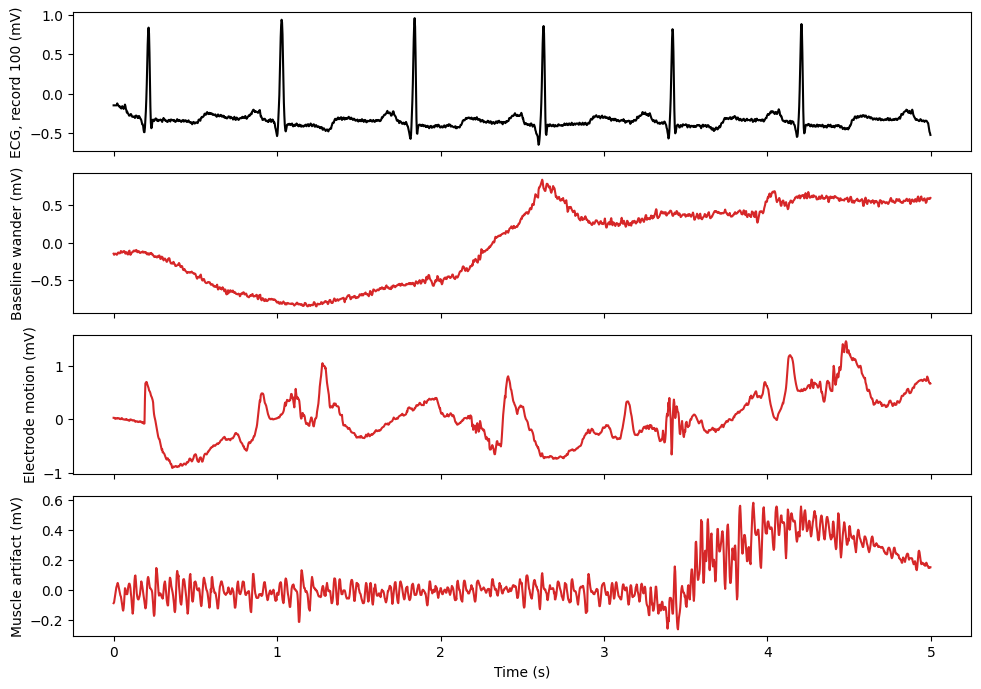

In [7]:
# Cell 7: visualize clean ECG and the three noise types
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
t = np.arange(5 * FS) / FS
axes[0].plot(t, ecg_signals["100"][:5 * FS], color="k")
axes[0].set_ylabel("ECG, record 100 (mV)")
for ax, name in zip(axes[1:], NOISE_NAMES):
    ax.plot(t, noise_signals[name][:5 * FS], color="tab:red")
    ax.set_ylabel(f"{NOISE_LABEL[name]} (mV)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Stage 3: Data preparation

This cell plots example ECG signals and noise signals to visually verify data quality.

In [8]:
# Cell 8: patient-disjoint main split and grouped cross-validation folds
patients = sorted(set(PATIENT.values()))


def records_of(plist):
    return [r for r in MIT_RECORDS if PATIENT[r] in plist]


order = np.random.default_rng(DATA_SEED).permutation(len(patients))
n_tr = round(SPLIT_FRAC["train"] * len(patients))
n_va = round(SPLIT_FRAC["val"] * len(patients))
patient_split = {}
for rank, idx in enumerate(order):
    patient_split[patients[idx]] = "train" if rank < n_tr else "val" if rank < n_tr + n_va else "test"
SPLIT_RECORDS = {s: [r for r in MIT_RECORDS if patient_split[PATIENT[r]] == s] for s in SPLITS}

folds = np.array_split(np.random.default_rng(CV_SEED).permutation(len(patients)), CV_FOLDS)
cv_partitions = []
for k in range(CV_FOLDS):
    te = {patients[i] for i in folds[k]}
    va = {patients[i] for i in folds[(k + 1) % CV_FOLDS]}
    tr = set(patients) - te - va
    cv_partitions.append({"train": records_of(tr), "val": records_of(va), "test": records_of(te)})

for s in SPLITS:
    print(s, len(SPLIT_RECORDS[s]), "records:", " ".join(SPLIT_RECORDS[s]))
print("cv test records per fold:", [len(p["test"]) for p in cv_partitions])

train 34 records: 103 104 105 106 107 109 111 116 117 118 119 122 123 200 201 202 203 205 207 208 209 210 212 213 215 220 221 222 223 228 230 231 232 234
val 7 records: 100 112 113 115 121 124 217
test 7 records: 101 102 108 114 214 219 233
cv test records per fold: [10, 10, 10, 9, 9]


In [9]:
# Cell 9: windows, intrinsic-quality filter (training-derived), unfiltered test windows, normalization
def extract_windows(split_records):
    raw, meta = {}, {}
    for s in SPLITS:
        chunks, rows = [], []
        for r in split_records[s]:
            sig = ecg_signals[r]
            n = len(sig) // WIN
            w = sig[: n * WIN].reshape(n, WIN)
            ok = np.isfinite(w).all(axis=1) & (w.std(axis=1) > MIN_STD)
            chunks.append(w[ok])
            rows += [(r, PATIENT[r], int(st)) for st in (np.arange(n) * WIN)[ok]]
        raw[s] = np.concatenate(chunks).astype(np.float32)
        meta[s] = pd.DataFrame(rows, columns=["record", "patient", "win_start"])
    return raw, meta


def quality_index(x):
    f, p = sps.welch(x, fs=FS, nperseg=WIN, detrend="constant", axis=1)

    def band(lo, hi):
        return p[:, (f >= lo) & (f <= hi)].sum(axis=1)

    return (band(0.5, 1.0) + band(40.0, 150.0)) / (band(0.5, 150.0) + 1e-12)


def prepare_ecg(split_records):
    raw, meta = extract_windows(split_records)
    qi = {s: quality_index(raw[s]) for s in SPLITS}
    thr = float(np.quantile(qi["train"], QC_KEEP_QUANTILE))
    info = dict(qc_threshold=thr, windows_before={s: len(raw[s]) for s in SPLITS})
    unf_raw = raw["test"].copy()
    unf_meta = meta["test"].copy()
    unf_meta["qc_index"] = qi["test"]
    unf_meta["qc_pass"] = qi["test"] <= thr
    for s in SPLITS:
        keep = qi[s] <= thr
        raw[s] = raw[s][keep]
        meta[s] = meta[s][keep].reset_index(drop=True)
        meta[s]["qc_index"] = qi[s][keep]
    info["windows_after"] = {s: len(raw[s]) for s in SPLITS}
    info["norm_mean"] = float(raw["train"].mean())
    info["norm_std"] = float(raw["train"].std())
    ecg = {s: ((raw[s] - info["norm_mean"]) / info["norm_std"]).astype(np.float32) for s in SPLITS}
    unf = dict(ecg=((unf_raw - info["norm_mean"]) / info["norm_std"]).astype(np.float32), meta=unf_meta)
    return ecg, meta, info, unf

In [10]:
# Cell 10: injected-noise generation (SNR is window-referenced; see protocol note)
NOISE_LEN = {n: len(noise_signals[n]) for n in NOISE_NAMES}
GUARD = GUARD_SEC * FS


def region(s, n):
    lo = int(NOISE_PART[s][0] * NOISE_LEN[n])
    hi = int(NOISE_PART[s][1] * NOISE_LEN[n])
    return (lo + GUARD if lo > 0 else lo, hi - GUARD if hi < NOISE_LEN[n] else hi)


noise_bounds = {s: {n: region(s, n) for n in NOISE_NAMES} for s in SPLITS}


def inject(ecg_win, noise_win, snr_db):
    # window-referenced injected SNR: P_window is the mean-removed power of the (possibly already noisy) ECG window
    s = ecg_win - ecg_win.mean()
    n = noise_win - noise_win.mean()
    n = n / (n.std() + 1e-12)
    scale = np.sqrt(np.mean(s ** 2) / 10 ** (snr_db / 10))
    return ecg_win + scale * n


def _noisy_split(ecg_arr, split, r):
    N = len(ecg_arr)
    y = np.arange(N) % 3
    r.shuffle(y)
    ntype = r.integers(0, len(NOISE_NAMES), N)
    ntype[y == 0] = -1
    snr = np.full(N, np.nan)
    for k, name in ((1, "mild"), (2, "severe")):
        m = y == k
        snr[m] = r.uniform(*SNR_RANGE[name], m.sum())
    nstart = np.full(N, -1, dtype=np.int64)
    x = ecg_arr.copy()
    for i in np.flatnonzero(y > 0):
        name = NOISE_NAMES[ntype[i]]
        lo, hi = noise_bounds[split][name]
        nstart[i] = r.integers(lo, hi - WIN + 1)
        x[i] = inject(ecg_arr[i], noise_signals[name][nstart[i]: nstart[i] + WIN], snr[i])
    return x, y, ntype, snr, nstart


def _label_meta(meta, y, ntype, snr, nstart):
    m = meta.copy()
    m["label"] = y
    m["label_name"] = np.array(CLASS_NAMES)[y]
    m["noise_type"] = np.where(ntype >= 0, np.array(NOISE_NAMES)[ntype], "none")
    m["snr_db"] = snr
    m["snr_target"] = np.where(y > 0, snr, SNR_CLEAN_TARGET)
    m["noise_start"] = nstart
    return m


def build_noisy(ecg, meta, seed):
    X, meta_out = {}, {}
    for s, off in zip(SPLITS, (1, 2, 3)):
        x, y, ntype, snr, nstart = _noisy_split(ecg[s], s, np.random.default_rng(seed + off))
        X[s], meta_out[s] = x, _label_meta(meta[s], y, ntype, snr, nstart)

    r = np.random.default_rng(seed + 4)
    N = len(ecg["test"])
    ntype = r.integers(0, len(NOISE_NAMES), N)
    snr = r.uniform(*SNR_INTERMEDIATE, N)
    nstart = np.empty(N, dtype=np.int64)
    x = ecg["test"].copy()
    for i in range(N):
        name = NOISE_NAMES[ntype[i]]
        lo, hi = noise_bounds["test"][name]
        nstart[i] = r.integers(lo, hi - WIN + 1)
        x[i] = inject(ecg["test"][i], noise_signals[name][nstart[i]: nstart[i] + WIN], snr[i])
    meta_inter = pd.DataFrame({"noise_type": np.array(NOISE_NAMES)[ntype], "snr_db": snr, "noise_start": nstart})
    return X, meta_out, x, meta_inter


def build_arrays(split_records, seed):
    ecg, meta0, info, unf = prepare_ecg(split_records)
    X, meta, X_inter, meta_inter = build_noisy(ecg, meta0, seed)
    x_unf, y, ntype, snr, nstart = _noisy_split(unf["ecg"], "test", np.random.default_rng(seed + 5))
    meta_unf = _label_meta(unf["meta"], y, ntype, snr, nstart)
    return dict(ecg=ecg, X=X, meta=meta, X_inter=X_inter, meta_inter=meta_inter, X_unf=x_unf, meta_unf=meta_unf,
                ecg_unf=unf["ecg"], info=info)

In [11]:
# Cell 11: main dataset, manifests, datasets and loaders
main = build_arrays(SPLIT_RECORDS, DATA_SEED)
ecg, X, meta, X_inter, meta_inter, info = (main[k] for k in ("ecg", "X", "meta", "X_inter", "meta_inter", "info"))
meta_unf, X_unf = main["meta_unf"], main["X_unf"]
print(f"quality filter threshold {info['qc_threshold']:.4f}; windows before {info['windows_before']} after {info['windows_after']}")
print(f"unfiltered test windows: {len(meta_unf)} ({int((~meta_unf.qc_pass).sum())} fail the filter)")

dist = pd.concat({s: meta[s].label_name.value_counts().reindex(CLASS_NAMES) for s in SPLITS}
                 | {"test_unfiltered": meta_unf.label_name.value_counts().reindex(CLASS_NAMES)}, axis=1)
display(dist)


def manifests_of(b):
    frames = {s: b["meta"][s] for s in SPLITS}
    frames["test_unfiltered"] = b["meta_unf"]
    frames["intermediate"] = b["meta_inter"]
    return frames


def save_manifests(b, tag):
    h = hashlib.sha256()
    for name, df in sorted(manifests_of(b).items()):
        df.to_csv(OUT["manifests"] / f"{tag}_{name}_manifest.csv.gz", index=False, compression="gzip")
        h.update(name.encode())
        h.update(df.to_csv(index=False).encode())
    return h.hexdigest()


MANIFEST_HASHES_PATH = OUT["manifests"] / "manifest_hashes.json"
MANIFEST_HASHES = json.loads(MANIFEST_HASHES_PATH.read_text()) if MANIFEST_HASHES_PATH.exists() else {}
MANIFEST_HASHES["main"] = save_manifests(main, "main")
MANIFEST_HASHES_PATH.write_text(json.dumps(MANIFEST_HASHES, indent=2))


class QualityDataset(Dataset):
    def __init__(self, x, y, snr_target):
        self.x = torch.from_numpy(x).unsqueeze(1)
        self.y = torch.from_numpy(np.asarray(y, dtype=np.int64))
        self.z = torch.from_numpy(((np.asarray(snr_target) - SNR_SHIFT) / SNR_SCALE).astype(np.float32))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i], self.z[i]


def attach_datasets(b):
    d = {s: QualityDataset(b["X"][s], b["meta"][s].label.values, b["meta"][s].snr_target.values) for s in SPLITS}
    d["inter"] = QualityDataset(b["X_inter"], np.zeros(len(b["X_inter"]), dtype=np.int64),
                                np.full(len(b["X_inter"]), SNR_SHIFT))
    d["unf"] = QualityDataset(b["X_unf"], b["meta_unf"].label.values, b["meta_unf"].snr_target.values)
    b["datasets"] = d
    b["eval"] = {s: DataLoader(d[s], batch_size=256, shuffle=False, pin_memory=PIN)
                 for s in ("val", "test", "inter", "unf")}
    return b


def make_loader(dataset, batch_size, seed):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=g, pin_memory=PIN)


main = attach_datasets(main)

quality filter threshold 0.1187; windows before {'train': 30668, 'val': 6314, 'test': 6314} after {'train': 21467, 'val': 3033, 'test': 4758}
unfiltered test windows: 6314 (1556 fail the filter)


,train,val,test,test_unfiltered
label_name,,,,
clean,7156,1011,1586,2105
mild,7156,1011,1586,2105
severe,7155,1011,1586,2104


## Stage 4: Statistical-feature baselines

**Why.** The deep models' advantage over interpretable features was the most reliable result of v2.1, so the baselines stay as the yardstick, now also evaluated on the unfiltered test windows.

**How.** Cell 12 computes amplitude, difference and spectral features. Cell 13 defines reusable fit and predict functions and fits the baselines on the main training partition. Test features are computed only at test-evaluation time.

In [12]:
# Cell 12: handcrafted quality indicators
BANDS = [(0, 1), (1, 5), (5, 15), (15, 40), (40, 150)]
FEATURE_NAMES = (["std", "ptp", "rms_diff", "mean_abs_diff", "max_abs_diff", "zero_cross", "skew", "kurtosis"]
                 + [f"band_{lo}_{hi}" for lo, hi in BANDS] + ["spec_entropy", "spec_centroid"])


def extract_features(x):
    xc = x - x.mean(axis=1, keepdims=True)
    d = np.diff(x, axis=1)
    f, p = sps.welch(x, fs=FS, nperseg=WIN, detrend="constant", axis=1)
    pn = p / (p.sum(axis=1, keepdims=True) + 1e-12)
    band = [pn[:, (f >= lo) & (f < hi)].sum(axis=1) for lo, hi in BANDS]
    entropy = -(pn * np.log(pn + 1e-12)).sum(axis=1)
    centroid = (pn * f).sum(axis=1)
    zero_cross = (np.signbit(xc[:, 1:]) != np.signbit(xc[:, :-1])).mean(axis=1)
    feats = np.column_stack([x.std(axis=1), np.ptp(x, axis=1), np.sqrt((d ** 2).mean(axis=1)),
                             np.abs(d).mean(axis=1), np.abs(d).max(axis=1), zero_cross,
                             skew(x, axis=1), kurtosis(x, axis=1), *band, entropy, centroid])
    return feats.astype(np.float32)

In [13]:
# Cell 13: baselines (fit on training; validation used only for the ridge thresholds)
def fit_baselines(b):
    feat = {s: extract_features(b["X"][s]) for s in ("train", "val")}
    models = {
        "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=DATA_SEED)),
        "random_forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=DATA_SEED),
        "ridge_snr": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    }
    ytr = b["meta"]["train"].label.values
    models["logreg"].fit(feat["train"], ytr)
    models["random_forest"].fit(feat["train"], ytr)
    models["ridge_snr"].fit(feat["train"], b["meta"]["train"].snr_target.values)
    return models, feat


def predict_baselines(models, b, feat_val):
    y_val = b["meta"]["val"].label.values
    thr = fit_thresholds(models["ridge_snr"].predict(feat_val), y_val)
    out = {}
    for es, key, xs in (("filtered", "test", b["X"]["test"]), ("unfiltered", "unf", b["X_unf"])):
        f = extract_features(xs)
        out[es] = {n: models[n].predict(f) for n in ("logreg", "random_forest")}
        out[es]["ridge_snr"] = apply_thresholds(models["ridge_snr"].predict(f), thr)
    return out, thr


baselines, FEAT = fit_baselines(main)
y_val = meta["val"].label.values
val_scores = {}
for n in ("logreg", "random_forest"):
    val_scores[n] = evaluate(y_val, baselines[n].predict(FEAT["val"]))
display(pd.DataFrame({k: {c: v[c] for c in METRIC_COLS} for k, v in val_scores.items()}).T.round(4))

,accuracy,macro_f1,macro_precision,macro_recall,qwk,adjacent_error,gross_error
logreg,0.6522,0.6233,0.6861,0.6522,0.7008,0.3109,0.0369
random_forest,0.7125,0.7076,0.7135,0.7125,0.7274,0.2552,0.0323


## Stage 5: Training functions, source audit and model runs

**Why.** The training recipe is unchanged from v2.1 so that v2.1 checkpoints are valid and comparable. What changes is the process: every checkpoint is registered with its provenance, the registry is backed up atomically after each run so an interrupted session can resume, reused v2.1 checkpoints are accepted only if they reproduce their recorded validation score on this exact dataset, and an audit verifies patient separation, noise-region separation, normalization, augmentation, checkpoint selection and test-set use before any model is trusted.

**How.** Cell 14 defines the architectures. Cell 15 defines training, checkpoint reuse, the registry and its backup. Cell 16 runs the audit. Cell 17 trains or reuses the main-split models without touching the test set.

In [14]:
# Cell 14: architectures (identical to v2.1 so that v2.1 checkpoints load)
class SE(nn.Module):
    def __init__(self, ch, reduction=4):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(ch, ch // reduction), nn.ReLU(), nn.Linear(ch // reduction, ch), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x.mean(dim=-1)).unsqueeze(-1)


def depthwise(ch, k):
    return nn.Sequential(nn.Conv1d(ch, ch, k, padding=k // 2, groups=ch), nn.BatchNorm1d(ch), nn.ReLU())


def pointwise(cin, cout):
    return nn.Sequential(nn.Conv1d(cin, cout, 1), nn.BatchNorm1d(cout), nn.ReLU())


class MultiScaleBlock(nn.Module):
    def __init__(self, ch, kernels=(3, 7, 15)):
        super().__init__()
        self.branches = nn.ModuleList(depthwise(ch, k) for k in kernels)
        self.fuse = pointwise(ch * len(kernels), ch)

    def forward(self, x):
        return self.fuse(torch.cat([b(x) for b in self.branches], dim=1))


def make_body(variant, ch):
    if variant == "M1":
        return nn.Sequential(nn.Conv1d(ch, ch, 7, padding=3), nn.BatchNorm1d(ch), nn.ReLU())
    if variant == "M3":
        return MultiScaleBlock(ch)
    if variant == "M4":
        return nn.Sequential(MultiScaleBlock(ch), SE(ch))
    raise ValueError(variant)


class QualityNet(nn.Module):
    def __init__(self, variant, depth=3, pool=True, use_std=True, dc="window", ordinal=False, base=16, dropout=0.2):
        super().__init__()
        self.dc, self.use_std, self.ordinal = dc, use_std, ordinal
        self.stem = nn.Sequential(nn.Conv1d(1, base, 7, padding=3), nn.BatchNorm1d(base), nn.ReLU())
        blocks = []
        for _ in range(depth):
            blocks.append(make_body(variant, base))
            if pool:
                blocks.append(nn.MaxPool1d(2))
        self.body = nn.Sequential(*blocks)
        feat = base * (2 if use_std else 1)
        self.drop = nn.Dropout(dropout)
        self.cls = nn.Linear(feat, 3)
        self.reg = nn.Linear(feat, 1)

    def forward(self, x):
        if self.dc == "window":
            x = x - x.mean(dim=-1, keepdim=True)
        h = self.body(self.stem(x))
        f = h.mean(dim=-1)
        if self.use_std:
            f = torch.cat([f, torch.sqrt(h.var(dim=-1, unbiased=False) + 1e-6)], dim=1)
        f = self.drop(f)
        return self.cls(f), self.reg(f).squeeze(-1)


def build_model(spec):
    return QualityNet(spec["variant"], spec["depth"], spec["pool"], spec["std"], spec["dc"], False,
                      TRAIN_CFG["base_channels"], TRAIN_CFG["dropout"])


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


display(pd.DataFrame([dict(model=k, parameters=count_params(build_model(s))) for k, s in MODEL_SPECS.items()]))

,model,parameters
0,M1-D3,5812
1,M3-D3,4372
2,M4-D3,4816
3,M4-D3nostd,4752


In [15]:
# Cell 15: training, checkpoint reuse with verification, registry with atomic backup
@torch.no_grad()
def ema_update(ema, model, decay):
    for pe, pm in zip(ema.parameters(), model.parameters()):
        pe.mul_(decay).add_(pm.detach(), alpha=1 - decay)
    for be, bm in zip(ema.buffers(), model.buffers()):
        be.copy_(bm)


@torch.no_grad()
def recalibrate_bn(net, loader, n_batches):
    bns = [m for m in net.modules() if isinstance(m, nn.BatchNorm1d)]
    for m in bns:
        m.reset_running_stats()
        m.momentum = None
    net.train()
    for i, (xb, *_) in enumerate(loader):
        if i >= n_batches:
            break
        net(xb.to(DEVICE))
    for m in bns:
        m.momentum = 0.1
    net.eval()


@torch.no_grad()
def predict(net, loader):
    net.eval()
    preds, probs, snr = [], [], []
    for xb, *_ in loader:
        lg, sp = net(xb.to(DEVICE))
        preds.append(lg.argmax(1).cpu())
        probs.append(torch.softmax(lg, 1).cpu())
        snr.append(sp.cpu())
    return (torch.cat(preds).numpy(), torch.cat(probs).numpy(), torch.cat(snr).numpy() * SNR_SCALE + SNR_SHIFT)


def train_model(model_id, seed, b, tag):
    spec = MODEL_SPECS[model_id]
    set_seed(seed)
    loader = make_loader(b["datasets"]["train"], TRAIN_CFG["batch_size"], seed)
    bn_loader = make_loader(b["datasets"]["train"], TRAIN_CFG["bn_recal_batch_size"], seed + 1)
    val_loader = b["eval"]["val"]
    y_val = b["meta"]["val"].label.values
    model = build_model(spec).to(DEVICE)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=TRAIN_CFG["lr"], weight_decay=TRAIN_CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=TRAIN_CFG["epochs"])
    ce, huber = nn.CrossEntropyLoss(), nn.SmoothL1Loss()
    ckpt = OUT["models"] / f"{tag}_{model_id}_seed{seed}.pt"
    hist, best, wait, best_epoch, best_f1 = [], -1.0, 0, 0, 0.0
    for epoch in range(1, TRAIN_CFG["epochs"] + 1):
        model.train()
        total, n = 0.0, 0
        for xb, yb, zb in loader:
            xb, yb, zb = xb.to(DEVICE), yb.to(DEVICE), zb.to(DEVICE)
            logits, sp = model(xb)
            loss = ce(logits, yb) + TRAIN_CFG["lambda_reg"] * huber(sp, zb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            ema_update(ema, model, TRAIN_CFG["ema_decay"])
            total += loss.item() * len(yb)
            n += len(yb)
        sched.step()
        recalibrate_bn(ema, bn_loader, TRAIN_CFG["bn_recal_batches"])
        pred, _, _ = predict(ema, val_loader)
        f1 = evaluate(y_val, pred)["macro_f1"]
        hist.append(dict(epoch=epoch, train_loss=total / n, val_macro_f1=f1, lr=opt.param_groups[0]["lr"]))
        smooth = float(np.mean([h["val_macro_f1"] for h in hist[-TRAIN_CFG["smooth_window"]:]]))
        hist[-1]["val_smoothed"] = smooth
        if epoch >= TRAIN_CFG["min_select_epoch"]:
            if smooth > best:
                best, wait, best_epoch, best_f1 = smooth, 0, epoch, float(f1)
                torch.save({"state_dict": ema.state_dict(), "epoch": epoch, "val_smoothed": smooth,
                            "val_macro_f1": float(f1), "model_id": model_id, "seed": seed}, ckpt)
            else:
                wait += 1
        if epoch % 10 == 0:
            print(f"  {tag} {model_id} seed {seed} epoch {epoch:02d} train_loss {total / n:.4f} val_macro_f1 {f1:.4f}")
        if epoch >= TRAIN_CFG["min_epochs"] and wait >= TRAIN_CFG["patience"]:
            break
    return dict(history=pd.DataFrame(hist), ckpt=ckpt, best_epoch=best_epoch, val_smoothed=best, val_f1_at_best=best_f1)


def load_ckpt(path):
    try:
        return torch.load(path, map_location=DEVICE)
    except Exception:
        return torch.load(path, map_location=DEVICE, weights_only=False)


def load_net(model_id, ckpt):
    net = build_model(MODEL_SPECS[model_id]).to(DEVICE)
    net.load_state_dict(load_ckpt(ckpt)["state_dict"])
    return net.eval()


REGISTRY_BACKUP_PATH = OUT_ROOT / "registry_backup.pkl"
if REGISTRY_BACKUP_PATH.exists():
    with open(REGISTRY_BACKUP_PATH, "rb") as f:
        registry = pickle.load(f)
    registry = {k: v for k, v in registry.items() if Path(v["ckpt"]).exists()}
    print(f"restored {len(registry)} completed runs from {REGISTRY_BACKUP_PATH}")
else:
    registry = {}


def save_registry():
    tmp = REGISTRY_BACKUP_PATH.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        pickle.dump(registry, f)
    os.replace(tmp, REGISTRY_BACKUP_PATH)


def obtain_run(model_id, seed, b, tag, bundle_hash):
    key = (tag, model_id, seed)
    if key in registry:
        return registry[key]
    dst = OUT["models"] / f"{tag}_{model_id}_seed{seed}.pt"
    source = None
    if dst.exists():
        source = "existing_v22"
    elif REUSE_V21 and V21_DIR is not None and (V21_DIR / "models" / dst.name).exists():
        shutil.copy2(V21_DIR / "models" / dst.name, dst)
        source = f"reused_v21:{V21_DIR / 'models' / dst.name}"
    if source is not None:
        ck = load_ckpt(dst)
        net = build_model(MODEL_SPECS[model_id]).to(DEVICE)
        net.load_state_dict(ck["state_dict"])
        pv, _, _ = predict(net, b["eval"]["val"])
        f1 = evaluate(b["meta"]["val"].label.values, pv)["macro_f1"]
        if abs(f1 - ck["val_macro_f1"]) < 1e-3:
            registry[key] = dict(ckpt=dst, source=source, best_epoch=int(ck["epoch"]), val_smoothed=float(ck["val_smoothed"]),
                                 val_f1_at_best=float(ck["val_macro_f1"]), val_f1_recomputed=float(f1), history=None,
                                 epochs_run=np.nan, collapsed_epochs=np.nan, seconds=0.0, manifest_hash=bundle_hash)
            save_registry()
            print(f"{tag} {model_id} seed {seed}: {source.split(':')[0]}, validation macro-F1 reproduced ({f1:.4f})")
            return registry[key]
        print(f"  {dst.name} does not reproduce its validation score on this dataset ({f1:.4f} vs {ck['val_macro_f1']:.4f}); retraining")
    t0 = time.perf_counter()
    r = train_model(model_id, seed, b, tag)
    h = r["history"]
    r.update(source="trained_v22", val_f1_recomputed=r["val_f1_at_best"], epochs_run=len(h),
             collapsed_epochs=int(((h.val_macro_f1 < 0.35) & (h.epoch > 5)).sum()), seconds=time.perf_counter() - t0,
             manifest_hash=bundle_hash)
    registry[key] = r
    save_registry()
    print(f"{tag} {model_id} seed {seed}: trained, smoothed val macro-F1 {r['val_smoothed']:.4f} at epoch {r['best_epoch']}, "
          f"{r['epochs_run']} epochs, {r['collapsed_epochs']} collapsed, {r['seconds']:.0f} s")
    return r

In [16]:
# Cell 16: audit of data separation, normalization, augmentation, checkpoint selection and test-set use
audit = []


def check(name, status, evidence):
    audit.append(dict(check=name, status=status, evidence=str(evidence)))


def source_of(fn):
    try:
        return inspect.getsource(fn)
    except (OSError, TypeError):
        return None


def source_check(name, fn, must=(), must_not=()):
    s = source_of(fn)
    if s is None:
        check(name, "SKIPPED", "source not available in this runtime")
        return
    bad = [m for m in must if m not in s] + [f"contains {m}" for m in must_not if m in s]
    check(name, "PASS" if not bad else "FAIL", "ok" if not bad else bad)


pset = {s: {PATIENT[r] for r in SPLIT_RECORDS[s]} for s in SPLITS}
check("Main split: patients disjoint", "PASS" if all(not (pset[a] & pset[b]) for a, b in
      (("train", "val"), ("train", "test"), ("val", "test"))) else "FAIL", {s: len(v) for s, v in pset.items()})
check("Main split: records 201 and 202 together", "PASS" if any({"201", "202"} <= set(v) for v in SPLIT_RECORDS.values())
      else "FAIL", [s for s, v in SPLIT_RECORDS.items() if "201" in v])
check("Main split: window patients belong to their partition", "PASS" if all(set(meta[s].patient) <= pset[s] for s in SPLITS)
      and set(meta_unf.patient) <= pset["test"] else "FAIL", "windows checked")
cv_ok, seen = True, []
for part in cv_partitions:
    ps = {s: {PATIENT[r] for r in part[s]} for s in SPLITS}
    cv_ok &= not (ps["train"] & ps["val"]) and not (ps["train"] & ps["test"]) and not (ps["val"] & ps["test"])
    cv_ok &= any({"201", "202"} <= set(v) for v in part.values())
    seen += sorted(ps["test"])
check("CV folds: disjoint partitions, every patient tested exactly once", "PASS" if cv_ok and sorted(seen) == patients else "FAIL",
      f"{len(seen)} test patients across {CV_FOLDS} folds")

guard_ok = all(noise_bounds["val"][n][0] - noise_bounds["train"][n][1] >= 2 * GUARD and
               noise_bounds["test"][n][0] - noise_bounds["val"][n][1] >= 2 * GUARD for n in NOISE_NAMES)
check("Noise regions: disjoint with guard intervals", "PASS" if guard_ok else "FAIL", f"guard {GUARD_SEC} s each side")
region_ok, span = True, {n: {} for n in NOISE_NAMES}
for s, m in (("train", meta["train"]), ("val", meta["val"]), ("test", meta["test"]), ("test", meta_unf)):
    noisy = m[m.label > 0]
    for n in NOISE_NAMES:
        sub = noisy[noisy.noise_type == n]
        lo, hi = noise_bounds[s][n]
        region_ok &= bool(((sub.noise_start >= lo) & (sub.noise_start + WIN <= hi)).all())
        if len(sub):
            a, z = int(sub.noise_start.min()), int(sub.noise_start.max() + WIN)
            span[n][s] = (min(a, span[n].get(s, (a, z))[0]), max(z, span[n].get(s, (a, z))[1]))
for n in NOISE_NAMES:
    sub = meta_inter[meta_inter.noise_type == n]
    lo, hi = noise_bounds["test"][n]
    region_ok &= bool(((sub.noise_start >= lo) & (sub.noise_start + WIN <= hi)).all())
check("Noise segments lie inside their partition's region (incl. unfiltered and intermediate sets)", "PASS" if region_ok else "FAIL", "all noisy windows")
overlap = [n for n in NOISE_NAMES if not (span[n]["train"][1] <= span[n]["val"][0] and span[n]["val"][1] <= span[n]["test"][0])]
check("Noise segments actually used do not overlap across partitions", "PASS" if not overlap else "FAIL", span)

check("Normalization: training windows standardized to mean 0, std 1; other partitions not re-standardized",
      "PASS" if abs(float(ecg["train"].mean())) < 1e-3 and abs(float(ecg["train"].std()) - 1) < 1e-3
      and abs(float(ecg["test"].std()) - 1) > 1e-6 else "FAIL",
      dict(train_mean=float(ecg["train"].mean()), train_std=float(ecg["train"].std()), test_std=float(ecg["test"].std())))
source_check("Source: normalization statistics and quality threshold come from the training partition only", prepare_ecg,
             must=('raw["train"].mean()', 'raw["train"].std()', 'qi["train"]'), must_not=('raw["test"].mean', 'raw["val"].mean'))
source_check("Source: dataset item access applies no random augmentation (noise is injected once, statically)",
             QualityDataset.__getitem__, must_not=("random", "rand", "noise"))

clean_ok = all(np.array_equal(X[s][meta[s].label.values == 0], ecg[s][meta[s].label.values == 0]) for s in SPLITS)
check("Clean windows are exactly the unmodified ECG windows", "PASS" if clean_ok and np.array_equal(
    X_unf[meta_unf.label.values == 0], main["ecg_unf"][meta_unf.label.values == 0]) else "FAIL", "array equality")
realized = []
for s, xs, es, m in (("train", X["train"], ecg["train"], meta["train"]), ("test", X["test"], ecg["test"], meta["test"]),
                     ("unf", X_unf, main["ecg_unf"], meta_unf)):
    idx = np.flatnonzero(m.label.values > 0)[:500]
    sig = es[idx] - es[idx].mean(axis=1, keepdims=True)
    noise = xs[idx] - es[idx]
    realized.append(float(np.abs(10 * np.log10((sig ** 2).mean(1) / (noise ** 2).mean(1)) - m.snr_db.values[idx]).max()))
check("Realized window-referenced SNR equals the sampled SNR", "PASS" if max(realized) < 1e-2 else "FAIL",
      f"max abs difference {max(realized):.2e} dB")
lab_ok = all(meta[s][meta[s].label == 1].snr_db.between(*SNR_RANGE["mild"]).all() and
             meta[s][meta[s].label == 2].snr_db.between(*SNR_RANGE["severe"]).all() for s in SPLITS)
check("Labels: mild 12-20 dB, severe 0-4 dB, 4-12 dB excluded from labeled sets", "PASS" if lab_ok and meta_inter.snr_db.between(
    *SNR_INTERMEDIATE).all() else "FAIL", "ranges verified")
source_check("Source: training and checkpoint selection use only training and validation loaders", train_model,
             must=('b["eval"]["val"]', 'b["datasets"]["train"]'), must_not=('"test"', "'test'", '"unf"', '"inter"'))
source_check("Source: baseline fitting uses only training and validation windows", fit_baselines,
             must=('("train", "val")',), must_not=('"test"', '"unf"'))
check("Test set untouched so far in this session", "PASS" if not TEST_LOG else "FAIL", f"{len(TEST_LOG)} test evaluations logged")
rate = {s: round(info["windows_after"][s] / info["windows_before"][s], 3) for s in SPLITS}
check("Quality filter retention (informational)", "INFO", f"{rate}; the filtered evaluation covers only windows that pass the filter")
check("Lead heterogeneity (informational)", "INFO", f"records using V5 instead of MLII: {mit_info[mit_info.used != 'MLII'].record.tolist()}")
check("Clean-class convention (informational)", "INFO", "clean = no injected noise; MIT-BIH windows contain intrinsic noise; 30 dB target is a convention")

if V21_DIR is not None and (V21_DIR / "manifests").exists():
    diffs = []
    for s in SPLITS:
        p = V21_DIR / "manifests" / f"{s}_manifest.csv"
        if not p.exists():
            continue
        old = pd.read_csv(p)
        common = [c for c in ("record", "patient", "win_start", "label", "noise_type", "noise_start") if c in old and c in meta[s]]
        same = len(old) == len(meta[s]) and all((old[c].astype(str).values == meta[s][c].astype(str).values).all() for c in common)
        same &= len(old) == len(meta[s]) and np.allclose(old.snr_db.values, meta[s].snr_db.values, equal_nan=True, atol=1e-6)
        diffs.append((s, bool(same)))
    check("Dataset reproduces the v2.1 manifests (train/val/test)", "PASS" if diffs and all(d for _, d in diffs) else "WARN", diffs)
else:
    check("Dataset reproduces the v2.1 manifests", "SKIPPED", "no v2.1 manifests available")

audit_df = pd.DataFrame(audit)
audit_df.to_csv(OUT["audit"] / "audit_report.csv", index=False)
display(audit_df)
assert not (audit_df.status == "FAIL").any(), audit_df[audit_df.status == "FAIL"]

,check,status,evidence
0,Main split: patients disjoint,PASS,"{'train': 33, 'val': 7, 'test': 7}"
1,Main split: records 201 and 202 together,PASS,['train']
2,Main split: window patients belong to their pa...,PASS,windows checked
3,"CV folds: disjoint partitions, every patient t...",PASS,47 test patients across 5 folds
4,Noise regions: disjoint with guard intervals,PASS,guard 5 s each side
5,Noise segments lie inside their partition's re...,PASS,all noisy windows
6,Noise segments actually used do not overlap ac...,PASS,"{'bw': {'train': (495, 388140), 'val': (391861..."
7,Normalization: training windows standardized t...,PASS,"{'train_mean': -1.7002386698550254e-07, 'train..."
8,Source: normalization statistics and quality t...,PASS,ok
9,Source: dataset item access applies no random ...,PASS,ok


In [17]:
# Cell 17: main-split models (reuse verified v2.1 checkpoints or train); no test-set access
t0 = time.perf_counter()
main_runs = {}
for mid in MODEL_SPECS:
    for seed in SEEDS_OF[mid]:
        main_runs[(mid, seed)] = obtain_run(mid, seed, main, "main", MANIFEST_HASHES["main"])
prov_main = pd.DataFrame([dict(model=m, seed=s, source=r["source"].split(":")[0], best_epoch=r["best_epoch"],
                               val_smoothed=r["val_smoothed"], val_f1=r["val_f1_recomputed"])
                          for (m, s), r in main_runs.items()])
display(prov_main.groupby(["model", "source"]).agg(n=("seed", "count"), best_epoch=("best_epoch", "mean"),
                                                   val_smoothed=("val_smoothed", "mean")).round(4))
print(f"main-split models ready in {time.perf_counter() - t0:.0f} s")

main M1-D3 seed 42: reused_v21, validation macro-F1 reproduced (0.6345)
main M1-D3 seed 123: reused_v21, validation macro-F1 reproduced (0.6713)
main M1-D3 seed 2026: reused_v21, validation macro-F1 reproduced (0.6214)
main M1-D3 seed 7: reused_v21, validation macro-F1 reproduced (0.6366)
main M1-D3 seed 99: reused_v21, validation macro-F1 reproduced (0.6343)
main M3-D3 seed 42: reused_v21, validation macro-F1 reproduced (0.7072)
main M3-D3 seed 123: reused_v21, validation macro-F1 reproduced (0.6839)
main M3-D3 seed 2026: reused_v21, validation macro-F1 reproduced (0.6992)
main M3-D3 seed 7: reused_v21, validation macro-F1 reproduced (0.6722)
main M3-D3 seed 99: reused_v21, validation macro-F1 reproduced (0.6446)
main M4-D3 seed 42: reused_v21, validation macro-F1 reproduced (0.6832)
main M4-D3 seed 123: reused_v21, validation macro-F1 reproduced (0.6850)
main M4-D3 seed 2026: reused_v21, validation macro-F1 reproduced (0.6837)
main M4-D3 seed 7: reused_v21, validation macro-F1 reprod

,,n,best_epoch,val_smoothed
model,source,,,
M1-D3,reused_v21,5,11.2000,0.6411
M3-D3,reused_v21,5,17.2000,0.6845
M4-D3,reused_v21,5,24.6000,0.6834
M4-D3nostd,reused_v21,3,24.6667,0.7051


main-split models ready in 4 s


## Stage 6: Efficiency, grouped cross-validation and the frozen selection

**Why.** Seven test patients cannot support a ranking of three similar architectures, and the same split has been used for many decisions. Grouped cross-validation tests every patient exactly once and supports patient-level resampling over 47 patients. The selection rule is written down and applied before the held-out split is evaluated, so the architecture decision cannot be influenced by it.

**How.** Cell 18 profiles cost on single-thread CPU. Cell 19 runs the 5-fold grouped cross-validation for the four models (3 seeds per fold, reusing verified v2.1 checkpoints where they exist), with per-run prediction caching so an interrupted run resumes. Cell 20 applies the frozen selection rule to the cross-validation results and writes the decision to disk.

In [18]:
# Cell 18: parameters, size, MACs, activation size, latency and throughput
def count_complexity(m):
    macs, acts, hooks = [0], [], []

    def conv_h(mod, i, o):
        macs[0] += o.numel() * (mod.in_channels // mod.groups) * mod.kernel_size[0]

    def lin_h(mod, i, o):
        macs[0] += mod.in_features * mod.out_features * (o.numel() // mod.out_features)

    def act_h(mod, i, o):
        acts.append(o.numel() * 4)

    for mod in m.modules():
        if isinstance(mod, nn.Conv1d):
            hooks.append(mod.register_forward_hook(conv_h))
        elif isinstance(mod, nn.Linear):
            hooks.append(mod.register_forward_hook(lin_h))
        if not list(mod.children()):
            hooks.append(mod.register_forward_hook(act_h))
    m.eval()
    with torch.no_grad():
        m(torch.zeros(1, 1, WIN))
    for h in hooks:
        h.remove()
    return macs[0], max(acts) / 1e6


def time_fn(fn, warmup, runs):
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(runs):
        s0 = time.perf_counter()
        fn()
        t.append((time.perf_counter() - s0) * 1000)
    return float(np.median(t)), float(np.percentile(t, 95))


def cpu_name():
    try:
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


prev_threads = torch.get_num_threads()
torch.set_num_threads(1)
x1 = torch.from_numpy(X["val"][:1]).unsqueeze(1)
xb = torch.from_numpy(X["val"][:TRAIN_CFG["batch_size"]]).unsqueeze(1)
nb = len(xb)

eff = {}
for mid, spec in MODEL_SPECS.items():
    net = build_model(spec).cpu().eval()
    buf = io.BytesIO()
    torch.save(net.state_dict(), buf)
    macs, peak_act_mb = count_complexity(copy.deepcopy(net))

    def infer1():
        with torch.inference_mode():
            net(x1)

    def inferb():
        with torch.inference_mode():
            net(xb)

    l1 = time_fn(infer1, 50, 300)
    lb = time_fn(inferb, 10, 30)
    eff[mid] = dict(parameters=count_params(net), size_mb=buf.getbuffer().nbytes / 1e6, macs_m=macs / 1e6,
                    flops_m=2 * macs / 1e6, peak_activation_mb=peak_act_mb, cpu_latency_ms_median=l1[0],
                    cpu_latency_ms_p95=l1[1], throughput_b1=1000 / l1[0], throughput_batch=nb / (lb[0] / 1000))

x1_np, xb_np = X["val"][:1], X["val"][:nb]
for name, mdl in baselines.items():
    est = copy.deepcopy(mdl)
    if name == "random_forest":
        est.set_params(n_jobs=1)
        n_params = sum(t.tree_.node_count for t in est.estimators_)
    else:
        n_params = est[-1].coef_.size + est[-1].intercept_.size
    l1 = time_fn(lambda: est.predict(extract_features(x1_np)), 20, 200)
    lb = time_fn(lambda: est.predict(extract_features(xb_np)), 5, 20)
    eff[name] = dict(parameters=n_params, size_mb=len(pickle.dumps(est)) / 1e6, macs_m=np.nan, flops_m=np.nan,
                     peak_activation_mb=np.nan, cpu_latency_ms_median=l1[0], cpu_latency_ms_p95=l1[1],
                     throughput_b1=1000 / l1[0], throughput_batch=nb / (lb[0] / 1000))
torch.set_num_threads(prev_threads)

efficiency_df = pd.DataFrame(eff).T
efficiency_df["parameters"] = efficiency_df["parameters"].astype(int)
HARDWARE = f"{cpu_name()}, {os.cpu_count()} logical cores, torch threads 1"
print(f"profiling hardware: {HARDWARE}; batch-1 latency, batch-{nb} throughput")
display(efficiency_df.round(4))

profiling hardware: Intel(R) Xeon(R) CPU @ 2.00GHz, 4 logical cores, torch threads 1; batch-1 latency, batch-64 throughput


,parameters,size_mb,macs_m,flops_m,peak_activation_mb,cpu_latency_ms_median,cpu_latency_ms_p95,throughput_b1,throughput_batch
M1-D3,5812,0.0337,2.3387,4.6774,0.0461,0.6465,0.7651,1546.6756,7315.5967
M3-D3,4372,0.0498,1.5524,3.1049,0.0461,2.6882,3.0520,371.9903,1616.4752
M4-D3,4816,0.0560,1.5528,3.1057,0.0461,3.0625,4.4832,326.5316,1519.3868
M4-D3nostd,4752,0.0558,1.5528,3.1055,0.0461,2.9502,3.2876,338.9546,1554.5455
logreg,48,0.0019,NaN,NaN,NaN,3.0266,3.5008,330.3993,13502.9045
random_forest,1006064,88.6016,NaN,NaN,NaN,13.6827,14.8570,73.0852,3684.7756
ridge_snr,16,0.0013,NaN,NaN,NaN,2.9529,4.1978,338.6466,14685.5766


In [19]:
# Cell 19: 5-fold grouped patient cross-validation (3 seeds per fold, resumable, predictions cached)
def pred_frame(b, out, tag, model, seed):
    frames = []
    for key, es, m in (("test", "filtered", b["meta"]["test"]), ("unf", "unfiltered", b["meta_unf"])):
        o = out[key]
        frames.append(pd.DataFrame({
            "tag": tag, "model": model, "seed": seed, "evalset": es, "win": np.arange(len(m)),
            "record": m.record.values, "patient": m.patient.values, "label": m.label.values,
            "noise_type": m.noise_type.values, "snr_db": m.snr_db.values, "qc_index": m.qc_index.values,
            "qc_pass": m.qc_pass.values if "qc_pass" in m.columns else True, "pred": o["pred"],
            "p0": o["prob"][:, 0] if o["prob"] is not None else np.nan,
            "p1": o["prob"][:, 1] if o["prob"] is not None else np.nan,
            "p2": o["prob"][:, 2] if o["prob"] is not None else np.nan,
            "snr_pred": o["snr"] if o["snr"] is not None else np.nan}))
    return pd.concat(frames, ignore_index=True)


def eval_run(net, b, with_inter=False):
    out = {}
    for key in ("test", "unf"):
        pred, prob, snr = predict(net, b["eval"][key])
        out[key] = dict(pred=pred, prob=prob, snr=snr)
    if with_inter:
        _, prob_i, snr_i = predict(net, b["eval"]["inter"])
        out["inter"] = dict(prob=prob_i, snr=snr_i)
    return out


def baseline_frame(b, preds, tag):
    frames = []
    for name in BASELINE_NAMES:
        out = {"test": dict(pred=preds["filtered"][name], prob=None, snr=None),
               "unf": dict(pred=preds["unfiltered"][name], prob=None, snr=None)}
        frames.append(pred_frame(b, out, tag, name, -1))
    return pd.concat(frames, ignore_index=True)


def cache_path(tag, model, seed):
    return OUT["predictions"] / f"{tag}_{model}_seed{seed}.csv.gz"


cv_frames = []
if RUN_CV:
    for k, part in enumerate(cv_partitions):
        tag = f"cv{k}"
        pending = [(m, s) for m in CV_MODELS for s in CV_SEEDS if not cache_path(tag, m, s).exists()]
        base_pending = not cache_path(tag, "baselines", -1).exists()
        if pending or base_pending:
            bk = attach_datasets(build_arrays(part, DATA_SEED + 100 * (k + 1)))
            MANIFEST_HASHES[tag] = save_manifests(bk, tag)
            MANIFEST_HASHES_PATH.write_text(json.dumps(MANIFEST_HASHES, indent=2))
            if base_pending:
                bl, ft = fit_baselines(bk)
                TEST_LOG.append(f"{tag}_baselines")
                bp, _ = predict_baselines(bl, bk, ft["val"])
                baseline_frame(bk, bp, tag).to_csv(cache_path(tag, "baselines", -1), index=False, compression="gzip")
            for m, s in pending:
                r = obtain_run(m, s, bk, tag, MANIFEST_HASHES[tag])
                TEST_LOG.append(f"{tag}_{m}_{s}")
                out = eval_run(load_net(m, r["ckpt"]), bk)
                pred_frame(bk, out, tag, m, s).to_csv(cache_path(tag, m, s), index=False, compression="gzip")
            del bk
        print(f"fold {k} complete")
    for p in sorted(OUT["predictions"].glob("cv*_*.csv.gz")):
        cv_frames.append(pd.read_csv(p, dtype={"patient": str, "record": str}))
cv_pred = pd.concat(cv_frames, ignore_index=True) if cv_frames else pd.DataFrame()
print(f"cross-validation predictions: {len(cv_pred)} rows from {len(cv_frames)} cached runs")

cv0 M1-D3 seed 42: reused_v21, validation macro-F1 reproduced (0.7929)
  cv0 M1-D3 seed 123 epoch 10 train_loss 0.5880 val_macro_f1 0.7640
  cv0 M1-D3 seed 123 epoch 20 train_loss 0.5326 val_macro_f1 0.7780
  cv0 M1-D3 seed 123 epoch 30 train_loss 0.5072 val_macro_f1 0.7870
  cv0 M1-D3 seed 123 epoch 40 train_loss 0.4920 val_macro_f1 0.7840
cv0 M1-D3 seed 123: trained, smoothed val macro-F1 0.7862 at epoch 31, 40 epochs, 0 collapsed, 78 s
  cv0 M1-D3 seed 2026 epoch 10 train_loss 0.5819 val_macro_f1 0.7582
  cv0 M1-D3 seed 2026 epoch 20 train_loss 0.5313 val_macro_f1 0.7765
  cv0 M1-D3 seed 2026 epoch 30 train_loss 0.4990 val_macro_f1 0.7882
  cv0 M1-D3 seed 2026 epoch 40 train_loss 0.4939 val_macro_f1 0.7873
cv0 M1-D3 seed 2026: trained, smoothed val macro-F1 0.7884 at epoch 34, 40 epochs, 0 collapsed, 74 s
cv0 M3-D3 seed 42: reused_v21, validation macro-F1 reproduced (0.8059)
  cv0 M3-D3 seed 123 epoch 10 train_loss 0.5149 val_macro_f1 0.7872
  cv0 M3-D3 seed 123 epoch 20 train_loss 

In [31]:
# Cell 20: frozen model-selection rule, applied to cross-validation results only 0.7331
def frame_metrics(df):
    m = evaluate(df.label.values, df.pred.values)
    out = {c: m[c] for c in METRIC_COLS}
    out.update({f"sens_{c}": m["sensitivity"][i] for i, c in enumerate(CLASS_NAMES)})
    noisy = df.label.values > 0
    ok = df.snr_pred.notna().values & noisy
    out["snr_mae"] = float(np.abs(df.snr_pred.values[ok] - df.snr_db.values[ok]).mean()) if ok.any() else np.nan
    out["n"] = len(df)
    return out


def metrics_by_run(frames):
    rows = [dict(evalset=es, tag=tag, model=model, seed=seed, **frame_metrics(g))
            for (es, tag, model, seed), g in frames.groupby(["evalset", "tag", "model", "seed"])]
    return pd.DataFrame(rows)


cv_runs = metrics_by_run(cv_pred)
cv_runs["fold"] = cv_runs.tag.str[2:].astype(int)
fold_df = cv_runs.groupby(["evalset", "model", "fold"])[METRIC_COLS + ["sens_clean", "sens_mild", "sens_severe", "snr_mae"]].mean().reset_index()


def t_ci(d, level=0.95):
    d = np.asarray(d, dtype=float)
    se = d.std(ddof=1) / np.sqrt(len(d))
    h = stats.t.ppf(0.5 + level / 2, len(d) - 1) * se
    return float(d.mean() - h), float(d.mean() + h)


def apply_rule(evalset):
    piv = fold_df[fold_df.evalset == evalset].pivot(index="fold", columns="model", values="macro_f1")
    means = piv[FROZEN_CANDIDATES].mean()
    best = means.idxmax()
    lat = {m: float(efficiency_df.loc[m, "cpu_latency_ms_median"]) for m in FROZEN_CANDIDATES}
    eligible = [m for m in sorted(FROZEN_CANDIDATES, key=lat.get) if means[m] >= means[best] - NONINFERIORITY_MARGIN]
    choice = eligible[0]
    detail = {}
    for m in FROZEN_CANDIDATES:
        if m != choice:
            d = piv[m] - piv[choice]
            detail[m] = dict(mean_diff_vs_choice=float(d.mean()), ci=t_ci(d))
    return dict(evalset=evalset, means={m: float(v) for m, v in means.items()}, best=best, choice=choice,
                eligible=eligible, latency_ms=lat, vs_choice=detail)


SELECTION_PATH = OUT["metrics"] / "frozen_selection.json"
if cv_pred.empty:
    raise RuntimeError("Cross-validation results are required to apply the frozen selection rule (set RUN_CV = True).")
rule = {es: apply_rule(es) for es in ("unfiltered", "filtered")}
if rule["unfiltered"]["choice"] == rule["filtered"]["choice"]:
    FROZEN_CHOICE, note = rule["unfiltered"]["choice"], "primary (unfiltered) and secondary (filtered) endpoints agree"
else:
    FROZEN_CHOICE = min(FROZEN_CANDIDATES, key=lambda m: efficiency_df.loc[m, "cpu_latency_ms_median"])
    note = "endpoints disagree; defaulted to the cheapest candidate"
exploratory_flag = {}
for m in EXPLORATORY_MODELS:
    es = "unfiltered"
    piv = fold_df[fold_df.evalset == es].pivot(index="fold", columns="model", values="macro_f1")
    gap = float(piv[m].mean() - piv[FROZEN_CHOICE].mean())
    exploratory_flag[m] = dict(mean_gap_vs_choice=gap, exceeds_margin=bool(gap > NONINFERIORITY_MARGIN),
                               status="exploratory only; cannot be declared the winner")
decision = dict(created=time.strftime("%Y-%m-%d %H:%M:%S"), protocol=PROTOCOL, config_hash=CONFIG_HASH, margin=NONINFERIORITY_MARGIN,
                rule="cheapest candidate within the margin of the best cross-validated macro-F1", candidates=FROZEN_CANDIDATES,
                endpoints=rule, frozen_choice=FROZEN_CHOICE, note=note, exploratory=exploratory_flag,
                evidence_hash=hashlib.sha256(fold_df.round(10).to_csv(index=False).encode()).hexdigest())
SELECTION_PATH.write_text(json.dumps(decision, indent=2, default=str))
print(json.dumps({k: decision[k] for k in ("frozen_choice", "note", "exploratory")}, indent=2, default=str))
for es in rule:
    print(es, {m: round(v, 4) for m, v in rule[es]["means"].items()}, "best:", rule[es]["best"], "choice:", rule[es]["choice"])

{
  "frozen_choice": "M1-D3",
  "note": "endpoints disagree; defaulted to the cheapest candidate",
  "exploratory": {
    "M4-D3nostd": {
      "mean_gap_vs_choice": 0.011905355555832053,
      "exceeds_margin": true,
      "status": "exploratory only; cannot be declared the winner"
    }
  }
}
unfiltered {'M1-D3': 0.7117, 'M3-D3': 0.7206, 'M4-D3': 0.7215} best: M4-D3 choice: M1-D3
filtered {'M1-D3': 0.7405, 'M3-D3': 0.7461, 'M4-D3': 0.7513} best: M4-D3 choice: M3-D3


## Stage 7: Held-out split (supplementary) and statistics

**Why.** After the rule has been applied, the 7-patient split is evaluated as supplementary evidence only. It has been seen in v2.0 and v2.1 and is therefore not an independent test, so it is never used to change the decision. Patient-level resampling over all 47 cross-validation patients is the main source of uncertainty estimates.

**How.** Cell 21 evaluates each main-split checkpoint once on the filtered and unfiltered test windows, checks that reused v2.1 checkpoints reproduce their v2.1 test scores, and evaluates the baselines. Cell 22 computes patient-level bootstrap intervals, paired fold tests and Holm correction for both evaluation sets.

In [21]:
# Cell 21: held-out split evaluation (supplementary), after the selection has been frozen
assert SELECTION_PATH.exists(), "freeze the selection (Cell 20) before evaluating the held-out split"
main_frames = []
for (mid, seed), r in sorted(main_runs.items(), key=lambda kv: (kv[0][1], kv[0][0])):
    TEST_LOG.append(f"main_{mid}_{seed}")
    out = eval_run(load_net(mid, r["ckpt"]), main)
    main_frames.append(pred_frame(main, out, "main", mid, seed))
TEST_LOG.append("main_baselines")
bp_main, base_thr = predict_baselines(baselines, main, FEAT["val"])
main_frames.append(baseline_frame(main, bp_main, "main"))
main_pred = pd.concat(main_frames, ignore_index=True)
main_pred.to_csv(OUT["predictions"] / "main_split_predictions.csv.gz", index=False, compression="gzip")
main_runs_df = metrics_by_run(main_pred)

repro = pd.DataFrame()
v21_path = V21_DIR / "metrics" / "test_results_per_run.csv" if V21_DIR is not None else None
if v21_path is not None and v21_path.exists():
    old = pd.read_csv(v21_path)
    old = old[old.rule == "cls"][["model", "seed", "macro_f1"]].rename(columns={"macro_f1": "macro_f1_v21"})
    new = main_runs_df[(main_runs_df.evalset == "filtered") & (main_runs_df.model.isin(MODEL_SPECS))][["model", "seed", "macro_f1"]]
    repro = new.merge(old, on=["model", "seed"])
    repro["abs_diff"] = (repro.macro_f1 - repro.macro_f1_v21).abs()
    reused = {(m, s) for (m, s), r in main_runs.items() if r["source"].startswith("reused")}
    repro = repro[[(m, s) in reused for m, s in zip(repro.model, repro.seed)]]
    print(f"v2.1 reproduction check on {len(repro)} reused checkpoints: max abs difference {repro.abs_diff.max():.2e}")
    assert repro.empty or repro.abs_diff.max() < 1e-3
summ = main_runs_df.groupby(["evalset", "model"])[["macro_f1", "accuracy", "qwk", "sens_clean", "sens_mild", "sens_severe", "snr_mae"]].agg(["mean", "std"])
display(summ.round(4))

v2.1 reproduction check on 18 reused checkpoints: max abs difference 0.00e+00


macro_f1         accuracy             qwk          \
                             mean     std     mean     std    mean     std   
evalset    model                                                             
filtered   M1-D3           0.7708  0.0096   0.7770  0.0085  0.8342  0.0060   
           M3-D3           0.7693  0.0068   0.7708  0.0059  0.8203  0.0078   
           M4-D3           0.7947  0.0087   0.7969  0.0091  0.8385  0.0101   
           M4-D3nostd      0.8004  0.0094   0.8012  0.0087  0.8427  0.0068   
           logreg          0.6593     NaN   0.6635     NaN  0.7000     NaN   
           random_forest   0.6700     NaN   0.6698     NaN  0.6962     NaN   
           ridge_snr       0.6424     NaN   0.6301     NaN  0.6885     NaN   
unfiltered M1-D3           0.7178  0.0067   0.7264  0.0059  0.7504  0.0054   
           M3-D3           0.7162  0.0080   0.7226  0.0071  0.7369  0.0092   
           M4-D3           0.7460  0.0102   0.7522  0.0095  0.7583  0.0117   
           M4-D3nostd      0.7524  0.0103   0.7580  0.0092  0.7641  0.0137   
           logreg          0.6019     NaN   0.6140     NaN  0.5875     NaN   
           random_forest   0.6102     NaN   0.6194     NaN  0.5863     NaN   
           ridge_snr       0.5717     NaN   0.5683     NaN  0.5727     NaN   

                         sens_clean         sens_mild         sens_severe  \
                               mean     std      mean     std        mean   
evalset    model                                                            
filtered   M1-D3             0.8508  0.0166    0.5352  0.0280      0.9450   
           M3-D3             0.7257  0.0186    0.6310  0.0295      0.9557   
           M4-D3             0.7615  0.0498    0.6628  0.0234      0.9663   
           M4-D3nostd        0.7266  0.0060    0.7093  0.0284      0.9676   
           logreg            0.7352     NaN    0.4130     NaN      0.8424   
           random_forest     0.6160     NaN    0.5246     NaN      0.8689   
           ridge_snr         0.5750     NaN    0.5876     NaN      0.7276   
unfiltered M1-D3             0.7265  0.0185    0.5136  0.0228      0.9392   
           M3-D3             0.6167  0.0183    0.5985  0.0264      0.9528   
           M4-D3             0.6716  0.0386    0.6228  0.0185      0.9624   
           M4-D3nostd        0.6461  0.0117    0.6602  0.0227      0.9678   
           logreg            0.6238     NaN    0.3739     NaN      0.8446   
           random_forest     0.5359     NaN    0.4537     NaN      0.8688   
           ridge_snr         0.4323     NaN    0.5435     NaN      0.7291   

                                 snr_mae          
                             std    mean     std  
evalset    model                                  
filtered   M1-D3          0.0095  4.7087  0.1228  
           M3-D3          0.0063  4.2208  0.0805  
           M4-D3          0.0051  3.5986  0.2131  
           M4-D3nostd     0.0042  3.2793  0.1934  
           logreg            NaN     NaN     NaN  
           random_forest     NaN     NaN     NaN  
           ridge_snr         NaN     NaN     NaN  
unfiltered M1-D3          0.0063  4.9790  0.0910  
           M3-D3          0.0060  4.4859  0.0687  
           M4-D3          0.0094  3.8131  0.1993  
           M4-D3nostd     0.0058  3.5318  0.1937  
           logreg            NaN     NaN     NaN  
           random_forest     NaN     NaN     NaN  
           ridge_snr         NaN     NaN     NaN

In [22]:
# Cell 22: patient-level bootstrap over all 47 cross-validation patients, fold-paired tests, Holm correction
def cms_by_patient(df, plist):
    idx = df.patient.map({p: i for i, p in enumerate(plist)}).values
    out = np.zeros((len(plist), 3, 3))
    np.add.at(out, (idx, df.label.values, df.pred.values), 1)
    return out


def collect_cms(frames, plist):
    res = {}
    for es in ("filtered", "unfiltered"):
        res[es] = {}
        sub = frames[frames.evalset == es]
        for (model, seed), g in sub.groupby(["model", "seed"]):
            res[es].setdefault(model, {})[seed] = cms_by_patient(g, plist)
    return res


def boot_series(cd, key, idx):
    return np.mean([f1_from_cms(c[idx].sum(axis=1)) for c in cd[key].values()], axis=0)


def point_est(cd, key):
    return float(np.mean([f1_from_cms(c.sum(axis=0)) for c in cd[key].values()]))


def pair_rows(cd, pairs, idx, fold_piv=None, margin=NONINFERIORITY_MARGIN):
    rows = []
    for a, b in pairs:
        if a not in cd or b not in cd:
            continue
        d = boot_series(cd, b, idx) - boot_series(cd, a, idx)
        lo, hi = np.percentile(d, [2.5, 97.5])
        row = dict(a=a, b=b, comparison=f"{a} to {b}", delta=point_est(cd, b) - point_est(cd, a), ci_lo=float(lo), ci_hi=float(hi),
                   p_patient_boot=float(min(1.0, 2 * min((d > 0).mean(), (d < 0).mean()))), a_noninferior_to_b=bool(hi < margin))
        if fold_piv is not None and a in fold_piv and b in fold_piv:
            diff = fold_piv[b] - fold_piv[a]
            row.update(fold_mean_delta=float(diff.mean()), fold_ci_lo=t_ci(diff)[0], fold_ci_hi=t_ci(diff)[1],
                       fold_p=float(stats.ttest_rel(fold_piv[b], fold_piv[a])[1]), folds_won=int((diff > 0).sum()))
        rows.append(row)
    pt = pd.DataFrame(rows)
    order_p = np.argsort(pt.p_patient_boot.values)
    adj, running = np.empty(len(order_p)), 0.0
    for rank, i in enumerate(order_p):
        running = max(running, (len(order_p) - rank) * pt.p_patient_boot.values[i])
        adj[i] = min(1.0, running)
    pt["p_holm"] = adj
    pt["verdict"] = np.where(pt.p_holm < 0.05, "supported", np.where((pt.ci_lo > 0) | (pt.ci_hi < 0), "suggestive (unadjusted)", "not supported"))
    return pt


PAIRS = [("M1-D3", "M3-D3"), ("M1-D3", "M4-D3"), ("M3-D3", "M4-D3"), ("M4-D3", "M4-D3nostd")]
PAIRS += [(b, c) for b in BASELINE_NAMES for c in FROZEN_CANDIDATES]
idx47 = np.random.default_rng(DATA_SEED).integers(0, len(patients), size=(N_BOOT, len(patients)))
cms_cv = collect_cms(cv_pred, patients)
pair_cv, ci_cv, point_cv = {}, {}, {}
for es in ("unfiltered", "filtered"):
    piv = fold_df[fold_df.evalset == es].pivot(index="fold", columns="model", values="macro_f1")
    pair_cv[es] = pair_rows(cms_cv[es], PAIRS, idx47, piv)
    ci_cv[es] = {k: tuple(np.percentile(boot_series(cms_cv[es], k, idx47), [2.5, 97.5])) for k in cms_cv[es]}
    point_cv[es] = {k: point_est(cms_cv[es], k) for k in cms_cv[es]}

main_patients = sorted(set(meta["test"].patient))
idx7 = np.random.default_rng(DATA_SEED).integers(0, len(main_patients), size=(N_BOOT, len(main_patients)))
cms_main = collect_cms(main_pred, main_patients)
pair_main, ci_main, point_main = {}, {}, {}
for es in ("unfiltered", "filtered"):
    pair_main[es] = pair_rows(cms_main[es], PAIRS, idx7)
    ci_main[es] = {k: tuple(np.percentile(boot_series(cms_main[es], k, idx7), [2.5, 97.5])) for k in cms_main[es]}
    point_main[es] = {k: point_est(cms_main[es], k) for k in cms_main[es]}

for es in ("unfiltered", "filtered"):
    print(f"--- cross-validation, {es} evaluation (47 patients) ---")
    display(pair_cv[es].drop(columns=["a", "b"]).round(4))

--- cross-validation, unfiltered evaluation (47 patients) ---


,comparison,delta,ci_lo,ci_hi,p_patient_boot,a_noninferior_to_b,fold_mean_delta,fold_ci_lo,fold_ci_hi,fold_p,folds_won,p_holm,verdict
0,M1-D3 to M3-D3,0.0090,-0.0018,0.0199,0.110,False,0.0089,0.0032,0.0146,0.0120,5,0.440,not supported
1,M1-D3 to M4-D3,0.0095,-0.0055,0.0223,0.204,False,0.0098,-0.0119,0.0315,0.2785,3,0.612,not supported
2,M3-D3 to M4-D3,0.0005,-0.0188,0.0172,0.955,False,0.0009,-0.0216,0.0233,0.9182,3,1.000,not supported
3,M4-D3 to M4-D3nostd,0.0019,-0.0077,0.0105,0.651,False,0.0021,-0.0039,0.0081,0.3816,4,1.000,not supported
4,logreg to M1-D3,0.1259,0.0904,0.1610,0.000,False,0.1242,0.0721,0.1764,0.0027,5,0.000,supported
5,logreg to M3-D3,0.1349,0.0974,0.1730,0.000,False,0.1331,0.0822,0.1841,0.0019,5,0.000,supported
6,logreg to M4-D3,0.1353,0.1005,0.1689,0.000,False,0.1340,0.0983,0.1698,0.0005,5,0.000,supported
7,random_forest to M1-D3,0.1500,0.1050,0.1982,0.000,False,0.1489,0.0974,0.2005,0.0013,5,0.000,supported
8,random_forest to M3-D3,0.1590,0.1109,0.2099,0.000,False,0.1578,0.1071,0.2086,0.0010,5,0.000,supported
9,random_forest to M4-D3,0.1595,0.1149,0.2065,0.000,False,0.1587,0.1227,0.1947,0.0003,5,0.000,supported


--- cross-validation, filtered evaluation (47 patients) ---


,comparison,delta,ci_lo,ci_hi,p_patient_boot,a_noninferior_to_b,fold_mean_delta,fold_ci_lo,fold_ci_hi,fold_p,folds_won,p_holm,verdict
0,M1-D3 to M3-D3,0.0054,-0.0066,0.0175,0.364,False,0.0055,-0.0010,0.0121,0.0788,4,1.0,not supported
1,M1-D3 to M4-D3,0.0090,-0.0068,0.0224,0.258,False,0.0108,-0.0168,0.0384,0.3378,4,1.0,not supported
2,M3-D3 to M4-D3,0.0036,-0.0189,0.0216,0.704,False,0.0053,-0.0245,0.0350,0.6491,4,1.0,not supported
3,M4-D3 to M4-D3nostd,-0.0039,-0.0145,0.0054,0.441,True,-0.0044,-0.0179,0.0091,0.4181,2,1.0,not supported
4,logreg to M1-D3,0.0929,0.0538,0.1236,0.000,False,0.0894,0.0363,0.1426,0.0095,5,0.0,supported
5,logreg to M3-D3,0.0984,0.0610,0.1308,0.000,False,0.0950,0.0435,0.1464,0.0069,5,0.0,supported
6,logreg to M4-D3,0.1020,0.0649,0.1326,0.000,False,0.1002,0.0647,0.1358,0.0014,5,0.0,supported
7,random_forest to M1-D3,0.1118,0.0613,0.1604,0.000,False,0.1038,0.0309,0.1768,0.0168,5,0.0,supported
8,random_forest to M3-D3,0.1173,0.0652,0.1681,0.000,False,0.1094,0.0357,0.1831,0.0146,5,0.0,supported
9,random_forest to M4-D3,0.1209,0.0736,0.1660,0.000,False,0.1146,0.0656,0.1637,0.0029,5,0.0,supported


## Stage 8: Mild-noise error investigation

**Why.** Mild noise (12-20 dB) is the hardest class for every model, and v2.1 left open whether the errors reflect the model, the label boundary, the noise type, particular patients or the intrinsic quality of the underlying window. Detection curves by SNR, error rates by noise type and SNR bin, per-patient sensitivity and example waveforms separate these explanations. Predictions are averaged over seeds so that individual training runs do not drive the picture.

**How.** Cell 23 builds seed-ensembled predictions and the detection, error and per-patient tables. Cell 24 plots detection curves and misclassified example windows.

In [23]:
# Cell 23: mild-noise error analysis tables (cross-validation pooled over all 47 patients)
def ensemble(frames):
    nn_frames = frames[frames.model.isin(MODEL_SPECS)]
    keys = ["evalset", "model", "tag", "win"]
    prob = nn_frames.groupby(keys)[["p0", "p1", "p2"]].mean()
    first = nn_frames.drop_duplicates(keys).set_index(keys)[["record", "patient", "label", "noise_type", "snr_db", "qc_index", "qc_pass"]]
    ens = first.join(prob).reset_index()
    ens["pred"] = ens[["p0", "p1", "p2"]].values.argmax(1)
    return ens


ens_cv = ensemble(cv_pred)
CAND = FROZEN_CANDIDATES
snr_bins = np.array([0, 2, 4, 12, 14, 16, 18, 20.01])
ens_cv["snr_bin"] = pd.cut(ens_cv.snr_db, snr_bins, right=False).astype(str)

detect = (ens_cv[(ens_cv.label > 0) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
          .assign(detected=lambda d: (d.pred != 0).astype(float))
          .groupby(["evalset", "model", "noise_type", "snr_bin"]).detected.agg(["mean", "count"]).reset_index())
false_alarm = (ens_cv[(ens_cv.label == 0) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)]
               .assign(alarm=lambda d: (d.pred != 0).astype(float))
               .groupby(["evalset", "model", "qc_pass"]).alarm.agg(["mean", "count"]).reset_index())

mild = ens_cv[(ens_cv.label == 1) & ens_cv.model.isin(CAND + EXPLORATORY_MODELS)].copy()
mild["mild_bin"] = np.where(mild.snr_db < 16, "12-16", "16-20")
mild_err = (mild.assign(to_clean=(mild.pred == 0), correct=(mild.pred == 1), to_severe=(mild.pred == 2))
            .groupby(["evalset", "model", "noise_type", "mild_bin"])[["correct", "to_clean", "to_severe"]].mean().reset_index())
mild_err["n"] = mild.groupby(["evalset", "model", "noise_type", "mild_bin"]).size().values

per_patient = (mild.assign(correct=(mild.pred == 1))
               .groupby(["evalset", "model", "patient"]).agg(n_mild=("correct", "size"), mild_sensitivity=("correct", "mean"),
                                                             mean_qc_index=("qc_index", "mean")).reset_index())
qc_effect = (mild.assign(to_clean=(mild.pred == 0))
             .groupby(["evalset", "model", "qc_pass"]).to_clean.agg(["mean", "count"]).reset_index())

pivot_err = mild_err[(mild_err.evalset == "filtered") & (mild_err.model == "M4-D3")].pivot(
    index="noise_type", columns="mild_bin", values="to_clean")
print("M4-D3, filtered evaluation: share of mild windows predicted clean, by noise type and SNR bin")
display(pivot_err.round(3))
print("false-alarm rate on clean windows (predicted noisy), by whether the base window passes the quality filter")
display(false_alarm[false_alarm.model.isin(CAND)].round(3))
print("mild windows predicted clean, by quality-filter status (unfiltered evaluation)")
display(qc_effect[(qc_effect.evalset == "unfiltered") & qc_effect.model.isin(CAND)].round(3))
worst = per_patient[(per_patient.evalset == "filtered") & (per_patient.model == "M4-D3")].sort_values("mild_sensitivity").head(8)
print("patients with the lowest mild-window sensitivity (M4-D3, filtered)")
display(worst.round(3))

M4-D3, filtered evaluation: share of mild windows predicted clean, by noise type and SNR bin


mild_bin,12-16,16-20
noise_type,,
bw,0.232,0.358
em,0.195,0.410
ma,0.059,0.161


false-alarm rate on clean windows (predicted noisy), by whether the base window passes the quality filter


,evalset,model,qc_pass,mean,count
0,filtered,M1-D3,True,0.330,10145
1,filtered,M3-D3,True,0.339,10145
2,filtered,M4-D3,True,0.357,10145
4,unfiltered,M1-D3,False,0.540,4309
5,unfiltered,M1-D3,True,0.326,10124
6,unfiltered,M3-D3,False,0.502,4309
7,unfiltered,M3-D3,True,0.329,10124
8,unfiltered,M4-D3,False,0.524,4309
9,unfiltered,M4-D3,True,0.353,10124


mild windows predicted clean, by quality-filter status (unfiltered evaluation)


,evalset,model,qc_pass,mean,count
4,unfiltered,M1-D3,False,0.179,4198
5,unfiltered,M1-D3,True,0.272,10235
6,unfiltered,M3-D3,False,0.174,4198
7,unfiltered,M3-D3,True,0.248,10235
8,unfiltered,M4-D3,False,0.150,4198
9,unfiltered,M4-D3,True,0.228,10235


patients with the lowest mild-window sensitivity (M4-D3, filtered)


,evalset,model,patient,n_mild,mild_sensitivity,mean_qc_index
103,filtered,M4-D3,112,254,0.035,0.093
117,filtered,M4-D3,205,272,0.180,0.020
110,filtered,M4-D3,121,9,0.222,0.099
130,filtered,M4-D3,222,16,0.312,0.083
123,filtered,M4-D3,213,293,0.314,0.041
132,filtered,M4-D3,228,22,0.318,0.076
93,filtered,M4-D3,101,245,0.355,0.051
118,filtered,M4-D3,207,45,0.378,0.056


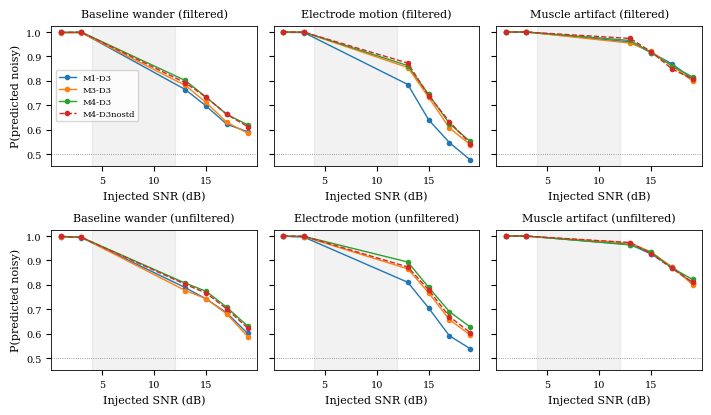

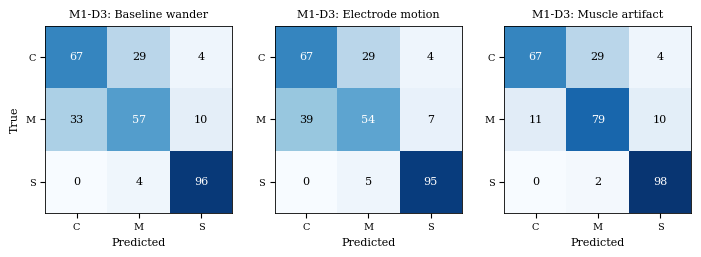

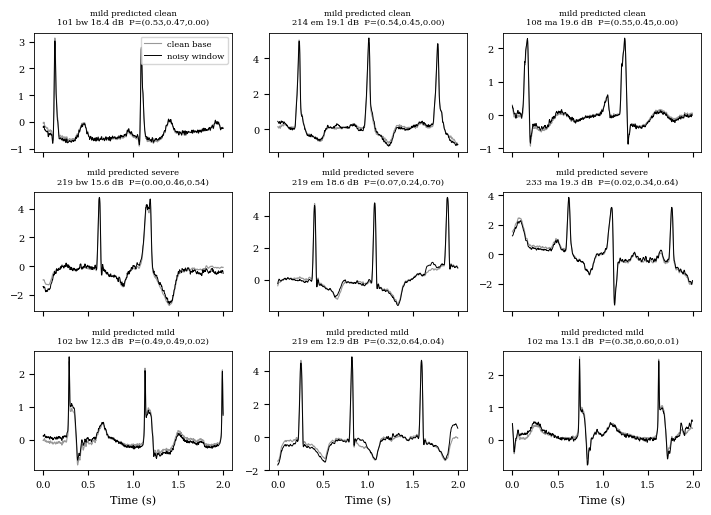

In [24]:
# Cell 24: detection curves, per-noise confusion and example misclassified mild windows
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
                     "legend.fontsize": 6, "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.linewidth": 0.6,
                     "lines.linewidth": 1.0, "savefig.dpi": 300, "savefig.bbox": "tight"})


def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(OUT["figures"] / f"{name}.{ext}")
    plt.show()


order_bins = ["[0.0, 2.0)", "[2.0, 4.0)", "[12.0, 14.0)", "[14.0, 16.0)", "[16.0, 18.0)", "[18.0, 20.01)"]
centers = [1, 3, 13, 15, 17, 19]
fig, axes = plt.subplots(2, 3, figsize=(7.16, 4.2), sharey=True)
for r_i, es in enumerate(("filtered", "unfiltered")):
    for ax, noise in zip(axes[r_i], NOISE_NAMES):
        for m in CAND + EXPLORATORY_MODELS:
            sub = detect[(detect.evalset == es) & (detect.model == m) & (detect.noise_type == noise)].set_index("snr_bin")
            ys = [sub["mean"].get(b, np.nan) for b in order_bins]
            ax.plot(centers, ys, marker="o", ms=3, ls="--" if m in EXPLORATORY_MODELS else "-", label=m)
        ax.axhline(0.5, color="gray", lw=0.6, ls=":")
        ax.axvspan(4, 12, color="gray", alpha=0.1)
        ax.set_title(f"{NOISE_LABEL[noise]} ({es})")
        ax.set_xlabel("Injected SNR (dB)")
axes[0, 0].set_ylabel("P(predicted noisy)")
axes[1, 0].set_ylabel("P(predicted noisy)")
axes[0, 0].legend()
fig.tight_layout()
save_fig(fig, "fig1_detection_curves")

fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.4))
sub = ens_cv[(ens_cv.evalset == "filtered") & (ens_cv.model == FROZEN_CHOICE)]
for ax, noise in zip(axes, NOISE_NAMES):
    s2 = sub[(sub.noise_type == noise) | (sub.label == 0)]
    cm = conf3(s2.label.values, s2.pred.values)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn[i, j] * 100:.0f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(["C", "M", "S"])
    ax.set_yticklabels(["C", "M", "S"])
    ax.set_title(f"{FROZEN_CHOICE}: {NOISE_LABEL[noise]}")
    ax.set_xlabel("Predicted")
axes[0].set_ylabel("True")
fig.tight_layout()
save_fig(fig, "fig2_confusion_by_noise")

ens_main = ensemble(main_pred[main_pred.model.isin(MODEL_SPECS)])
em = ens_main[(ens_main.evalset == "filtered") & (ens_main.model == FROZEN_CHOICE)].set_index("win")
rng_ex = np.random.default_rng(DATA_SEED)
rows_spec = [("mild predicted clean", (em.label == 1) & (em.pred == 0) & (em.snr_db >= 16)),
             ("mild predicted severe", (em.label == 1) & (em.pred == 2)),
             ("mild predicted mild", (em.label == 1) & (em.pred == 1) & (em.snr_db < 14))]
fig, axes = plt.subplots(3, 3, figsize=(7.16, 5.2), sharex=True)
for r_i, (title, mask) in enumerate(rows_spec):
    for c_i, noise in enumerate(NOISE_NAMES):
        ax = axes[r_i, c_i]
        cand = em.index[mask & (em.noise_type == noise)]
        if len(cand) == 0:
            ax.set_axis_off()
            continue
        i = int(rng_ex.choice(cand))
        row = em.loc[i]
        ax.plot(np.arange(WIN) / FS, main["ecg"]["test"][i], color="0.6", lw=0.8, label="clean base")
        ax.plot(np.arange(WIN) / FS, main["X"]["test"][i], color="k", lw=0.7, label="noisy window")
        ax.set_title(f"{title}\n{row.record} {noise} {row.snr_db:.1f} dB  P=({row.p0:.2f},{row.p1:.2f},{row.p2:.2f})", fontsize=6)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
axes[0, 0].legend()
fig.tight_layout()
save_fig(fig, "fig3_misclassified_mild_examples")

## Stage 9: Figures, tables and findings

**Why.** Figures, tables and the findings text are generated from stored results so they cannot drift from the numbers, and the findings text states the frozen selection and uses the word "supported" only where the corrected patient-level statistics support it.

**How.** Cell 25 writes the remaining figures. Cell 26 writes CSV and LaTeX tables. Cell 27 generates the findings.

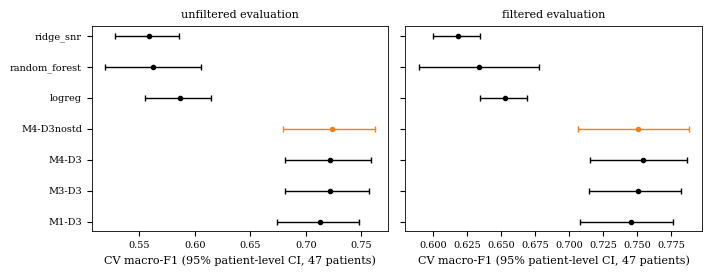

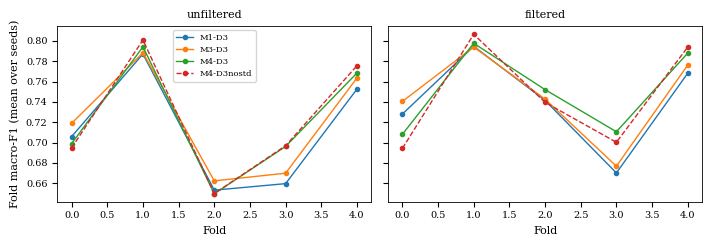

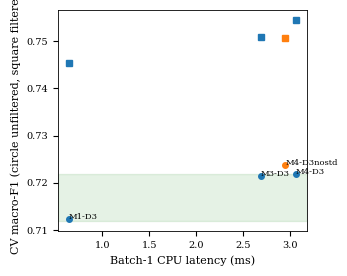

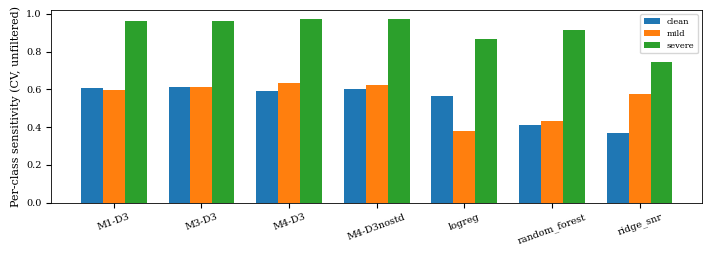

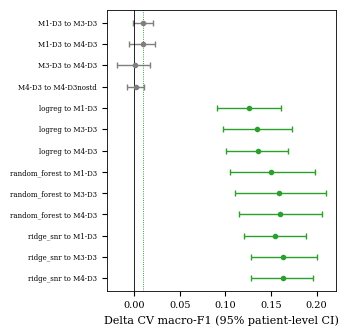

In [25]:
# Cell 25: cross-validation evidence figures
VMARK = {"M1": "o", "M3": "^", "M4": "D"}
fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.8), sharey=True)
keys = CV_MODELS + BASELINE_NAMES
for ax, es in zip(axes, ("unfiltered", "filtered")):
    for i, k in enumerate(keys):
        p, (lo, hi) = point_cv[es][k], ci_cv[es][k]
        ax.errorbar(p, i, xerr=[[p - lo], [hi - p]], fmt="o", color="tab:orange" if k in EXPLORATORY_MODELS else "k", capsize=2, ms=3)
    ax.set_yticks(range(len(keys)))
    ax.set_yticklabels(keys)
    ax.invert_yaxis()
    ax.set_title(f"{es} evaluation")
    ax.set_xlabel("CV macro-F1 (95% patient-level CI, 47 patients)")
fig.tight_layout()
save_fig(fig, "fig4_cv_patient_ci")

fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.5), sharey=True)
for ax, es in zip(axes, ("unfiltered", "filtered")):
    piv = fold_df[fold_df.evalset == es].pivot(index="fold", columns="model", values="macro_f1")
    for m in CV_MODELS:
        ax.plot(piv.index, piv[m], marker="o", ms=3, ls="--" if m in EXPLORATORY_MODELS else "-", label=m)
    ax.set_xlabel("Fold")
    ax.set_title(es)
axes[0].set_ylabel("Fold macro-F1 (mean over seeds)")
axes[0].legend()
fig.tight_layout()
save_fig(fig, "fig5_cv_fold_paired")

fig, ax = plt.subplots(figsize=(3.5, 2.8))
for m in CV_MODELS:
    xs = efficiency_df.loc[m, "cpu_latency_ms_median"]
    for es, mk in (("unfiltered", "o"), ("filtered", "s")):
        ax.plot(xs, point_cv[es][m], mk, color="tab:orange" if m in EXPLORATORY_MODELS else "tab:blue", ms=4)
    ax.annotate(m, (xs, point_cv["unfiltered"][m]), fontsize=6)
best_f = max(point_cv["unfiltered"][m] for m in FROZEN_CANDIDATES)
ax.axhspan(best_f - NONINFERIORITY_MARGIN, best_f, color="green", alpha=0.1)
ax.set_xlabel("Batch-1 CPU latency (ms)")
ax.set_ylabel("CV macro-F1 (circle unfiltered, square filtered)")
fig.tight_layout()
save_fig(fig, "fig6_accuracy_latency")

fig, ax = plt.subplots(figsize=(7.16, 2.6))
names = CV_MODELS + BASELINE_NAMES
cvs = cv_runs[cv_runs.evalset == "unfiltered"].groupby("model")[["sens_clean", "sens_mild", "sens_severe"]].mean()
for j, c in enumerate(CLASS_NAMES):
    ax.bar(np.arange(len(names)) + (j - 1) * 0.25, [cvs.loc[n, f"sens_{c}"] for n in names], 0.25, label=c)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=20)
ax.set_ylabel("Per-class sensitivity (CV, unfiltered)")
ax.legend()
fig.tight_layout()
save_fig(fig, "fig7_per_class_sensitivity")

pt = pair_cv["unfiltered"].iloc[::-1].reset_index(drop=True)
colors = {"supported": "tab:green", "suggestive (unadjusted)": "tab:orange", "not supported": "tab:gray"}
fig, ax = plt.subplots(figsize=(3.5, 0.2 * len(pt) + 0.8))
for i, r in pt.iterrows():
    ax.errorbar(r.delta, i, xerr=[[r.delta - r.ci_lo], [r.ci_hi - r.delta]], fmt="o", color=colors[r.verdict], capsize=2, ms=3)
ax.axvline(0, color="k", lw=0.6)
ax.axvline(NONINFERIORITY_MARGIN, color="green", lw=0.6, ls=":")
ax.set_yticks(range(len(pt)))
ax.set_yticklabels(pt.comparison, fontsize=5)
ax.set_xlabel("Delta CV macro-F1 (95% patient-level CI)")
fig.tight_layout()
save_fig(fig, "fig8_pairwise_effects")

In [26]:
# Cell 26: tables
def pm(mean, std):
    return f"{mean:.3f}" if pd.isna(std) else f"{mean:.3f} ± {std:.3f}"


def save_table(df, name, caption, label):
    df.to_csv(OUT["tables"] / f"{name}.csv", index=False)
    tex = df.to_latex(index=False, float_format="%.3f", caption=caption, label=label, escape=True)
    (OUT["tables"] / f"{name}.tex").write_text(tex.replace("±", r"$\pm$"))
    display(df)


t_part = pd.DataFrame([dict(Partition=s, Patients=meta[s].patient.nunique(), Records=meta[s].record.nunique(),
                            Windows_before_filter=info["windows_before"][s], Windows=len(meta[s])) for s in SPLITS]
                      + [dict(Partition="test (unfiltered)", Patients=meta_unf.patient.nunique(), Records=meta_unf.record.nunique(),
                              Windows_before_filter=len(meta_unf), Windows=len(meta_unf))])
rows = []
for es in ("unfiltered", "filtered"):
    sub = fold_df[fold_df.evalset == es]
    for m in CV_MODELS + BASELINE_NAMES:
        g = sub[sub.model == m]
        lo, hi = ci_cv[es][m]
        rows.append({"Evaluation": es, "Model": m + (" (exploratory)" if m in EXPLORATORY_MODELS else ""),
                     "Macro-F1 (SD over folds)": pm(g.macro_f1.mean(), g.macro_f1.std()),
                     "95% patient CI": f"[{lo:.3f}, {hi:.3f}]", "QWK": round(g.qwk.mean(), 3),
                     "Sens. clean": round(g.sens_clean.mean(), 3), "Sens. mild": round(g.sens_mild.mean(), 3),
                     "Sens. severe": round(g.sens_severe.mean(), 3),
                     "SNR MAE (dB)": np.nan if g.snr_mae.isna().all() else round(g.snr_mae.mean(), 2),
                     "Parameters": int(efficiency_df.loc[m, "parameters"]),
                     "CPU latency (ms)": round(efficiency_df.loc[m, "cpu_latency_ms_median"], 3)})
t_cv = pd.DataFrame(rows)
t_pairs = pd.concat([pair_cv[es].assign(Evaluation=es) for es in pair_cv]).drop(columns=["a", "b"]).rename(columns={
    "comparison": "Comparison", "delta": "Delta macro-F1", "ci_lo": "CI low", "ci_hi": "CI high",
    "p_patient_boot": "p (patient bootstrap)", "p_holm": "p (Holm)", "verdict": "Verdict", "fold_p": "p (paired folds)",
    "folds_won": "Folds won", "a_noninferior_to_b": "Cheaper model non-inferior"})
t_main = main_runs_df.groupby(["evalset", "model"])[["macro_f1", "accuracy", "qwk", "sens_clean", "sens_mild", "sens_severe", "snr_mae"]].agg(["mean", "std"])
t_main.columns = [f"{a}_{b}" for a, b in t_main.columns]
t_main = t_main.reset_index()
t_eff = efficiency_df.reset_index().rename(columns={"index": "Model"})
t_sel = pd.DataFrame([dict(Endpoint=es, Best=rule[es]["best"], Chosen=rule[es]["choice"], **{f"Mean {m}": round(v, 4) for m, v in rule[es]["means"].items()})
                      for es in rule] + [dict(Endpoint="FROZEN CHOICE", Best="", Chosen=FROZEN_CHOICE)])
t_mild = mild_err.copy()

save_table(t_part, "table1_partitions", "Dataset partitions (patient-disjoint), filtered and unfiltered test windows.", "tab:partitions")
save_table(t_cv, "table2_cross_validation", "Grouped patient cross-validation (primary evidence): macro-F1 by evaluation set.", "tab:cv")
save_table(t_pairs, "table3_cv_pairwise", "Pairwise comparisons: patient-level bootstrap, Holm correction, paired folds.", "tab:cvpairs")
save_table(t_sel, "table4_frozen_selection", "Frozen selection rule outcome.", "tab:selection")
save_table(t_main, "table5_main_split_supplementary", "Held-out 7-patient split (supplementary).", "tab:main")
save_table(t_eff, "table6_efficiency", f"Computational cost (single-thread CPU: {HARDWARE}).", "tab:efficiency")
save_table(t_mild, "table7_mild_errors", "Mild-window outcomes by noise type and SNR bin (CV pooled, seed-ensembled).", "tab:mild")
save_table(per_patient, "table8_per_patient_mild_sensitivity", "Per-patient mild sensitivity (CV pooled, seed-ensembled).", "tab:patient")

,Partition,Patients,Records,Windows_before_filter,Windows
0,train,33,34,30668,21467
1,val,7,7,6314,3033
2,test,7,7,6314,4758
3,test (unfiltered),7,7,6314,6314


,Evaluation,Model,Macro-F1 (SD over folds),95% patient CI,QWK,Sens. clean,Sens. mild,Sens. severe,SNR MAE (dB),Parameters,CPU latency (ms)
0,unfiltered,M1-D3,0.712 ± 0.058,"[0.674, 0.747]",0.716,0.607,0.594,0.960,4.25,5812,0.647
1,unfiltered,M3-D3,0.721 ± 0.056,"[0.681, 0.756]",0.725,0.612,0.615,0.960,4.12,4372,2.688
2,unfiltered,M4-D3,0.722 ± 0.059,"[0.681, 0.758]",0.724,0.589,0.632,0.971,3.77,4816,3.062
3,unfiltered,M4-D3nostd (exploratory),0.724 ± 0.063,"[0.680, 0.762]",0.720,0.603,0.623,0.972,3.66,4752,2.950
4,unfiltered,logreg,0.587 ± 0.060,"[0.555, 0.614]",0.553,0.565,0.379,0.866,NaN,48,3.027
5,unfiltered,random_forest,0.563 ± 0.045,"[0.519, 0.605]",0.469,0.409,0.430,0.913,NaN,1006064,13.683
6,unfiltered,ridge_snr,0.557 ± 0.053,"[0.528, 0.586]",0.530,0.370,0.575,0.747,NaN,16,2.953
7,filtered,M1-D3,0.741 ± 0.047,"[0.708, 0.777]",0.774,0.670,0.610,0.958,4.20,5812,0.647
8,filtered,M3-D3,0.746 ± 0.045,"[0.714, 0.782]",0.779,0.654,0.639,0.959,4.04,4372,2.688
9,filtered,M4-D3,0.751 ± 0.042,"[0.716, 0.787]",0.781,0.641,0.659,0.970,3.68,4816,3.062


,Comparison,Delta macro-F1,CI low,CI high,p (patient bootstrap),Cheaper model non-inferior,fold_mean_delta,fold_ci_lo,fold_ci_hi,p (paired folds),Folds won,p (Holm),Verdict,Evaluation
0,M1-D3 to M3-D3,0.009005,-0.001798,0.019921,0.110,False,0.008909,0.003248,0.014569,0.011970,5,0.440,not supported,unfiltered
1,M1-D3 to M4-D3,0.009477,-0.005531,0.022346,0.204,False,0.009793,-0.011911,0.031497,0.278528,3,0.612,not supported,unfiltered
2,M3-D3 to M4-D3,0.000472,-0.018758,0.017231,0.955,False,0.000884,-0.021564,0.023333,0.918167,3,1.000,not supported,unfiltered
3,M4-D3 to M4-D3nostd,0.001878,-0.007704,0.010517,0.651,False,0.002112,-0.003858,0.008082,0.381582,4,1.000,not supported,unfiltered
4,logreg to M1-D3,0.125860,0.090393,0.160954,0.000,False,0.124232,0.072063,0.176401,0.002713,5,0.000,supported,unfiltered
5,logreg to M3-D3,0.134865,0.097408,0.172984,0.000,False,0.133141,0.082154,0.184127,0.001921,5,0.000,supported,unfiltered
6,logreg to M4-D3,0.135337,0.100493,0.168888,0.000,False,0.134025,0.098297,0.169753,0.000480,5,0.000,supported,unfiltered
7,random_forest to M1-D3,0.149983,0.105005,0.198245,0.000,False,0.148918,0.097357,0.200478,0.001312,5,0.000,supported,unfiltered
8,random_forest to M3-D3,0.158987,0.110902,0.209886,0.000,False,0.157827,0.107099,0.208554,0.000988,5,0.000,supported,unfiltered
9,random_forest to M4-D3,0.159460,0.114933,0.206450,0.000,False,0.158711,0.122728,0.194694,0.000255,5,0.000,supported,unfiltered


,Endpoint,Best,Chosen,Mean M1-D3,Mean M3-D3,Mean M4-D3
0,unfiltered,M4-D3,M1-D3,0.7117,0.7206,0.7215
1,filtered,M4-D3,M3-D3,0.7405,0.7461,0.7513
2,FROZEN CHOICE,,M1-D3,NaN,NaN,NaN


,evalset,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,qwk_mean,qwk_std,sens_clean_mean,sens_clean_std,sens_mild_mean,sens_mild_std,sens_severe_mean,sens_severe_std,snr_mae_mean,snr_mae_std
0,filtered,M1-D3,0.770788,0.009635,0.777007,0.008502,0.834198,0.005960,0.850820,0.016626,0.535183,0.027990,0.945019,0.009493,4.708735,0.122848
1,filtered,M3-D3,0.769254,0.006824,0.770828,0.005933,0.820284,0.007765,0.725725,0.018624,0.631021,0.029457,0.955738,0.006327,4.220771,0.080524
2,filtered,M4-D3,0.794653,0.008704,0.796889,0.009131,0.838522,0.010148,0.761538,0.049806,0.662799,0.023399,0.966330,0.005134,3.598593,0.213119
3,filtered,M4-D3nostd,0.800411,0.009378,0.801177,0.008739,0.842703,0.006834,0.726566,0.005993,0.709332,0.028359,0.967633,0.004198,3.279303,0.193388
4,filtered,logreg,0.659297,NaN,0.663514,NaN,0.699970,NaN,0.735183,NaN,0.412989,NaN,0.842371,NaN,NaN,NaN
5,filtered,random_forest,0.669968,NaN,0.669819,NaN,0.696222,NaN,0.616015,NaN,0.524590,NaN,0.868852,NaN,NaN,NaN
6,filtered,ridge_snr,0.642418,NaN,0.630097,NaN,0.688514,NaN,0.575032,NaN,0.587642,NaN,0.727617,NaN,NaN,NaN
7,unfiltered,M1-D3,0.717777,0.006730,0.726386,0.005896,0.750408,0.005409,0.726461,0.018480,0.513634,0.022804,0.939163,0.006314,4.978969,0.090955
8,unfiltered,M3-D3,0.716188,0.007964,0.722616,0.007118,0.736866,0.009197,0.616722,0.018299,0.598480,0.026408,0.952757,0.006008,4.485947,0.068722
9,unfiltered,M4-D3,0.746013,0.010152,0.752233,0.009546,0.758339,0.011686,0.671639,0.038600,0.622803,0.018482,0.962357,0.009376,3.813111,0.199346


,Model,parameters,size_mb,macs_m,flops_m,peak_activation_mb,cpu_latency_ms_median,cpu_latency_ms_p95,throughput_b1,throughput_batch
0,M1-D3,5812,0.033731,2.338688,4.677376,0.04608,0.646548,0.765062,1546.675576,7315.596669
1,M3-D3,4372,0.049798,1.552448,3.104896,0.04608,2.688243,3.051958,371.990250,1616.475216
2,M4-D3,4816,0.056041,1.552832,3.105664,0.04608,3.062490,4.483162,326.531625,1519.386788
3,M4-D3nostd,4752,0.055785,1.552768,3.105536,0.04608,2.950248,3.287593,338.954556,1554.545479
4,logreg,48,0.001854,NaN,NaN,NaN,3.026640,3.500773,330.399332,13502.904496
5,random_forest,1006064,88.601587,NaN,NaN,NaN,13.682665,14.857031,73.085177,3684.775621
6,ridge_snr,16,0.001298,NaN,NaN,NaN,2.952930,4.197835,338.646643,14685.576641


,evalset,model,noise_type,mild_bin,correct,to_clean,to_severe,n
0,filtered,M1-D3,bw,12-16,0.608955,0.268657,0.122388,1675
1,filtered,M1-D3,bw,16-20,0.535651,0.392457,0.071892,1697
2,filtered,M1-D3,em,12-16,0.628319,0.284956,0.086726,1695
3,filtered,M1-D3,em,16-20,0.457734,0.486486,0.055779,1739
4,filtered,M1-D3,ma,12-16,0.811976,0.062275,0.125749,1670
5,filtered,M1-D3,ma,16-20,0.769323,0.160575,0.070102,1669
6,filtered,M3-D3,bw,12-16,0.629851,0.253134,0.117015,1675
7,filtered,M3-D3,bw,16-20,0.537419,0.391279,0.071302,1697
8,filtered,M3-D3,em,12-16,0.712094,0.204720,0.083186,1695
9,filtered,M3-D3,em,16-20,0.519839,0.425532,0.054629,1739


,evalset,model,patient,n_mild,mild_sensitivity,mean_qc_index
0,filtered,M1-D3,100,285,0.484211,0.055287
1,filtered,M1-D3,101,245,0.318367,0.050507
2,filtered,M1-D3,102,316,0.556962,0.068834
3,filtered,M1-D3,103,304,0.457237,0.021569
4,filtered,M1-D3,104,100,0.530000,0.106347
...,...,...,...,...,...,...
367,unfiltered,M4-D3nostd,230,313,0.785942,0.068745
368,unfiltered,M4-D3nostd,231,297,0.555556,0.153429
369,unfiltered,M4-D3nostd,232,306,0.915033,0.121240
370,unfiltered,M4-D3nostd,233,306,0.696078,0.062902


In [27]:
# Cell 27: findings generated from the computed statistics
sel = json.loads(SELECTION_PATH.read_text())
lines = [f"Experiment Protocol {PROTOCOL}; frozen candidates {FROZEN_CANDIDATES}; exploratory {EXPLORATORY_MODELS}.",
         "Scope: single-lead ECG signal-quality assessment of injected-noise level (clean/mild/severe) with an auxiliary SNR output; "
         "not an arrhythmia classifier or a denoiser; labels are not independently validated absolute quality.",
         f"Frozen selection (applied to cross-validation before the held-out split was evaluated): {sel['frozen_choice']} ({sel['note']}).",
         f"Rule: {sel['rule']}, margin {sel['margin']}."]
for es in ("unfiltered", "filtered"):
    lines.append(f"Cross-validation, {es} evaluation (macro-F1 mean over folds [95% patient CI over 47 patients]):")
    for m in CV_MODELS + BASELINE_NAMES:
        g = fold_df[(fold_df.evalset == es) & (fold_df.model == m)]
        lo, hi = ci_cv[es][m]
        tagx = " (exploratory)" if m in EXPLORATORY_MODELS else ""
        lines.append(f"- {m}{tagx}: {g.macro_f1.mean():.3f} (SD over folds {g.macro_f1.std():.3f}) [{lo:.3f}, {hi:.3f}], "
                     f"sens {g.sens_clean.mean():.2f}/{g.sens_mild.mean():.2f}/{g.sens_severe.mean():.2f}.")
fu = fold_df[fold_df.evalset == "filtered"].groupby("model").macro_f1.mean()
uu = fold_df[fold_df.evalset == "unfiltered"].groupby("model").macro_f1.mean()
lines.append("Unfiltered minus filtered macro-F1: " + ", ".join(f"{m} {uu[m] - fu[m]:+.3f}" for m in CV_MODELS + BASELINE_NAMES) + ".")
for es in ("unfiltered", "filtered"):
    lines.append(f"Pairwise comparisons, {es} (Holm-adjusted patient-level bootstrap):")
    for r in pair_cv[es].itertuples():
        extra = f", folds won {int(r.folds_won)}/{CV_FOLDS}, fold p {r.fold_p:.3f}" if hasattr(r, "folds_won") and not pd.isna(r.folds_won) else ""
        ni = "; cheaper model non-inferior within the margin" if r.a_noninferior_to_b and r.a in FROZEN_CANDIDATES and r.b in FROZEN_CANDIDATES else ""
        direction = "" if r.verdict == "not supported" else (" (second model better)" if r.delta > 0 else " (second model worse)")
        lines.append(f"- {r.comparison}: delta {r.delta:+.4f}, CI [{r.ci_lo:+.4f}, {r.ci_hi:+.4f}], Holm p {r.p_holm:.3f}{extra}: {r.verdict}{direction}{ni}.")
lines.append("Held-out 7-patient split (supplementary, not independent: it was used in v2.0 and v2.1):")
for es in ("unfiltered", "filtered"):
    for m in CV_MODELS:
        g = main_runs_df[(main_runs_df.evalset == es) & (main_runs_df.model == m)]
        lo, hi = ci_main[es][m]
        lines.append(f"- {m}, {es}: {g.macro_f1.mean():.3f} (SD over seeds {g.macro_f1.std():.3f}) [{lo:.3f}, {hi:.3f}].")
mdet = mild_err[(mild_err.evalset == "filtered") & (mild_err.model == FROZEN_CHOICE)]
hard = mdet.sort_values("to_clean", ascending=False).head(1).iloc[0]
lines.append(f"Mild-noise errors ({FROZEN_CHOICE}, filtered CV): the most frequent failure is mild predicted clean for {NOISE_LABEL[hard.noise_type]} at {hard.mild_bin} dB "
             f"({hard.to_clean:.2f} of {int(hard.n)} windows).")
fa = false_alarm[(false_alarm.evalset == "unfiltered") & (false_alarm.model == FROZEN_CHOICE)].set_index("qc_pass")["mean"]
if {True, False} <= set(fa.index):
    lines.append(f"Clean-window false-alarm rate for {FROZEN_CHOICE}: {fa[True]:.3f} when the base window passes the quality filter, {fa[False]:.3f} when it fails.")
low = per_patient[(per_patient.evalset == "filtered") & (per_patient.model == FROZEN_CHOICE)].mild_sensitivity
lines.append(f"Per-patient mild sensitivity ({FROZEN_CHOICE}): median {low.median():.2f}, range {low.min():.2f}-{low.max():.2f} across {len(low)} patients.")
lines += [
    "Limitations:",
    "- The model estimates the level of injected noise on MIT-BIH windows; MIT-BIH windows are not noise-free, the clean class is defined by the absence of injection, and the 30 dB clean SNR target is a modeling convention.",
    "- SNR is window-referenced (injected noise relative to total window power), not true signal-to-noise.",
    "- Training uses filtered windows only; the unfiltered evaluation tests robustness to windows the filter would have removed but is not a substitute for external validation on naturally corrupted, expert-labeled recordings.",
    "- Noise comes from three NSTDB source recordings, split by time; this is a controlled robustness test, not evidence of generalization to unseen recording environments.",
    "- The 7-patient held-out split was reused across v2.0 and v2.1 and is supplementary only; cross-validation uses 1 split per patient with 3 seeds per fold.",
    "- Many comparisons were run; Holm correction is applied to the patient-level bootstrap p-values, but the analysis remains exploratory until confirmed on an independent test.",
    "- Hyperparameters were fixed across architectures and not tuned per model.",
    "- Multi-scale convolution and squeeze-and-excitation are established techniques; any novelty claim must rest on the demonstrated design and experiment after checking related literature.",
    f"- Latency is measured on the notebook CPU ({HARDWARE}), not on a wearable or edge device.",
]
summary = "\n".join(lines)
(OUT["metrics"] / "findings.txt").write_text(summary)
print(summary)

Experiment Protocol v2.2; frozen candidates ['M1-D3', 'M3-D3', 'M4-D3']; exploratory ['M4-D3nostd'].
Scope: single-lead ECG signal-quality assessment of injected-noise level (clean/mild/severe) with an auxiliary SNR output; not an arrhythmia classifier or a denoiser; labels are not independently validated absolute quality.
Frozen selection (applied to cross-validation before the held-out split was evaluated): M1-D3 (endpoints disagree; defaulted to the cheapest candidate).
Rule: cheapest candidate within the margin of the best cross-validated macro-F1, margin 0.01.
Cross-validation, unfiltered evaluation (macro-F1 mean over folds [95% patient CI over 47 patients]):
- M1-D3: 0.712 (SD over folds 0.058) [0.674, 0.747], sens 0.61/0.59/0.96.
- M3-D3: 0.721 (SD over folds 0.056) [0.681, 0.756], sens 0.61/0.62/0.96.
- M4-D3: 0.722 (SD over folds 0.059) [0.681, 0.758], sens 0.59/0.63/0.97.
- M4-D3nostd (exploratory): 0.724 (SD over folds 0.063) [0.680, 0.762], sens 0.60/0.62/0.97.
- logreg: 0

## Stage 10: Export, provenance and final checks

**Why.** Every reported number must be reproducible from the exact checkpoint and dataset manifest that produced it. That requires recording the checkpoint hash, where it came from, the manifest hash of the dataset bundle it was evaluated on, and the configuration hash, and confirming that the preserved v2.1 outputs were not modified.

**How.** Cell 28 writes the provenance table, configuration, environment and a reproduction guide. Cell 29 verifies hashes, one-time test use, prediction coverage and the integrity of the preserved v2.1 copy, then checksums and archives the outputs.

In [28]:
# Cell 28: provenance, configuration and reproduction guide
prov = pd.DataFrame([dict(tag=t, model=m, seed=s, checkpoint=str(r["ckpt"].relative_to(OUT_ROOT)), checkpoint_sha256=sha256_file(r["ckpt"]),
                          source=r["source"], val_macro_f1_recorded=r["val_f1_at_best"], val_macro_f1_recomputed=r["val_f1_recomputed"],
                          best_epoch=r["best_epoch"], dataset_manifest_hash=r["manifest_hash"], config_hash=CONFIG_HASH)
                     for (t, m, s), r in sorted(registry.items())])
prov.to_csv(OUT["metrics"] / "provenance.csv", index=False)

run_summary = pd.DataFrame([dict(tag=t, model=m, seed=s, source=r["source"].split(":")[0], best_epoch=r["best_epoch"],
                                 epochs_run=r["epochs_run"], collapsed_epochs=r["collapsed_epochs"], val_smoothed=r["val_smoothed"])
                            for (t, m, s), r in sorted(registry.items())])
run_summary.to_csv(OUT["metrics"] / "run_summary.csv", index=False)
histories = [r["history"].assign(tag=t, model=m, seed=s) for (t, m, s), r in registry.items() if r["history"] is not None]
if histories:
    pd.concat(histories).to_csv(OUT["metrics"] / "training_histories_v22.csv", index=False)

cv_runs.to_csv(OUT["metrics"] / "cv_run_metrics.csv", index=False)
fold_df.to_csv(OUT["metrics"] / "cv_fold_metrics.csv", index=False)
main_runs_df.to_csv(OUT["metrics"] / "main_split_run_metrics.csv", index=False)
for es in pair_cv:
    pair_cv[es].to_csv(OUT["metrics"] / f"cv_pairwise_{es}.csv", index=False)
    pair_main[es].to_csv(OUT["metrics"] / f"main_pairwise_{es}.csv", index=False)
efficiency_df.to_csv(OUT["metrics"] / "efficiency.csv")
detect.to_csv(OUT["metrics"] / "mild_detection_curves.csv", index=False)
mild_err.to_csv(OUT["metrics"] / "mild_error_breakdown.csv", index=False)
per_patient.to_csv(OUT["metrics"] / "per_patient_mild_sensitivity.csv", index=False)
if not repro.empty:
    repro.to_csv(OUT["metrics"] / "v21_reproduction_check.csv", index=False)

env = dict(python=platform.python_version(), torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__,
           scipy=__import__("scipy").__version__, sklearn=__import__("sklearn").__version__, wfdb=wfdb.__version__,
           device=str(DEVICE), hardware=HARDWARE)
(OUT["metrics"] / "experiment_config.json").write_text(json.dumps(dict(config=CONFIG, config_hash=CONFIG_HASH, environment=env,
    patient_split=patient_split, split_records=SPLIT_RECORDS, cv_partitions=cv_partitions, noise_bounds=noise_bounds,
    qc_info=info, manifest_hashes=MANIFEST_HASHES, v21_source=str(V21_SRC), v21_preserved=str(V21_DIR)), indent=2, default=str))
(OUT_ROOT / "REPRODUCE.md").write_text(
    "# Reproducing Protocol v2.2 results\n\n"
    "1. Use the same PhysioNet MIT-BIH and NSTDB files (record names and sample counts are listed in experiment_config.json).\n"
    "2. Run the notebook with the configuration hash printed in Cell 3 and stored in experiment_config.json.\n"
    "3. Dataset bundles are regenerated deterministically from DATA_SEED; compare their hashes with manifests/manifest_hashes.json.\n"
    "4. Each checkpoint in models/ is identified in metrics/provenance.csv by SHA-256, its source (trained here or reused from the preserved v2.1 copy) "
    "and the manifest hash of the dataset it was evaluated on.\n"
    "5. metrics/frozen_selection.json records the architecture decision and the hash of the cross-validation evidence it was based on.\n")
display(prov.groupby(["tag", "source"]).size().unstack(fill_value=0).head(10))

source,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv0_M1-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv0_M3-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv0_M4-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv1_M1-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv1_M3-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv1_M4-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv2_M1-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv2_M3-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv2_M4-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/cv3_M1-D3_seed42.pt,...,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M3-D3_seed99.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M4-D3_seed123.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M4-D3_seed2026.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M4-D3_seed42.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M4-D3_seed7.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M4-D3_seed99.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M4-D3nostd_seed123.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M4-D3nostd_seed2026.pt,reused_v21:/kaggle/working/preserved_runs/ecg_quality_v21_20261027_155438/models/main_M4-D3nostd_seed42.pt,trained_v22
tag,,,,,,,,,,,,,,,,,,,,,
cv0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
cv1,0,0,0,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
cv2,0,0,0,0,0,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,9
cv3,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,9
cv4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
main,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,0


In [29]:
# Cell 29: final checks and packaging
expected_main = [f"main_{m}_{s}" for (m, s) in main_runs] + ["main_baselines"]
logged = Counter(TEST_LOG)
assert all(c == 1 for c in logged.values()), [k for k, c in logged.items() if c > 1]
assert set(expected_main) <= set(TEST_LOG), set(expected_main) - set(TEST_LOG)

if RUN_CV:
    expected_cv = [cache_path(f"cv{k}", m, s) for k in range(CV_FOLDS) for m in CV_MODELS for s in CV_SEEDS] + \
                  [cache_path(f"cv{k}", "baselines", -1) for k in range(CV_FOLDS)]
    assert all(p.exists() for p in expected_cv), [p.name for p in expected_cv if not p.exists()]
    assert cv_pred[(cv_pred.evalset == "unfiltered") & cv_pred.model.isin(MODEL_SPECS)].groupby(["model", "seed"]).patient.nunique().eq(len(patients)).all()

assert SELECTION_PATH.exists() and json.loads(SELECTION_PATH.read_text())["frozen_choice"] in FROZEN_CANDIDATES
assert json.loads(SELECTION_PATH.read_text())["frozen_choice"] == FROZEN_CHOICE

bad = [r.checkpoint for r in prov.itertuples() if sha256_file(OUT_ROOT / r.checkpoint) != r.checkpoint_sha256]
assert not bad, bad
assert all(abs(r.val_macro_f1_recorded - r.val_macro_f1_recomputed) < 1e-3 for r in prov.itertuples())

if V21_SRC is not None and V21_DIR is not None:
    changed = [rel for rel, h in V21_MANIFEST.items() if (V21_SRC / rel).exists() and sha256_file(V21_SRC / rel) != h]
    changed += [rel for rel, h in V21_MANIFEST.items() if sha256_file(V21_DIR / rel) != h]
    assert not changed, f"v2.1 files differ from their preservation manifest: {changed[:5]}"
    print(f"v2.1 outputs verified unchanged ({len(V21_MANIFEST)} files)")

files = sorted(p for p in OUT_ROOT.rglob("*") if p.is_file() and p.name != "checksums.json")
(OUT_ROOT / "checksums.json").write_text(json.dumps({str(p.relative_to(OUT_ROOT)): sha256_file(p) for p in files}, indent=2))
archive = shutil.make_archive(str(ROOT / "ecg_quality_v22_package"), "zip", OUT_ROOT)
print(f"all checks passed, {len(files)} files, archive: {archive}")

v2.1 outputs verified unchanged (155 files)
all checks passed, 228 files, archive: /kaggle/working/ecg_quality_v22_package.zip
